# ECM514 — Projeto 2: Detecção e Diagnóstico de Falhas em Rolamentos (IMS/NASA)

**Objetivos**
1. **Detectar anomalias** (Normal × Falha): TPR, FPR, ROC/AUC e antecedência da detecção.
2. **Diagnosticar o tipo de falha** (Normal / Pista externa / Pista interna / Rolo): matriz de confusão 4×4 e acurácia por classe.

**Técnicas**
- Técnica 1: classificadores supervisionados sobre features físicas — Random Forest (Breiman 2001) e SVC (Cortes & Vapnik 1995)
  em destaque; KNN e Árvore de Decisão na comparação (scikit-learn; Pedregosa et al. 2011).
- Técnica 2: CNN 1D pequena (Keras) sobre o sinal bruto (Ince et al. 2016; Zhang et al. 2017), comparada com um
  `MLPClassifier` sobre as features.
- Detecção: D1 (limiar μ+3σ), D2 (PCA + KMeans só no Normal) e D3 (classificador binário + ROC).

**Cuidados contra vazamento:** 1 linha = 1 snapshot; split **temporal** por (ensaio, rolamento, classe) — 70% iniciais no treino;
CV com `StratifiedKFold(5, shuffle=False)` (blocos contíguos); scaler/PCA ajustados só no treino (dentro de `Pipeline`);
janelas da CNN herdam o lado do snapshot. Há `assert` em cada etapa.

**Como rodar:** `Executar tudo`. Com `USAR_CACHE = True` (padrão) os dados vêm do cache (`data/`); a execução completa
leva ~12 min numa CPU de 12 núcleos (mais no Colab; a CNN é a etapa mais longa).

## 0. Setup
Clona o repositório (no Colab), instala só o que falta, fixa as seeds e obtém os dados por uma de 3 rotas:
1. cache local em `data/` (`features.parquet` + `cnn_cache.npz`);
2. download do cache (zip publicado como *release* do repositório, `URL_CACHE`);
3. reconstrução a partir do bruto: download do IMS via `kagglehub` + extração das features + cache da CNN (~10–20 min).

In [1]:
import os
import sys
import subprocess
import importlib.util
import time
from pathlib import Path

REPO_URL = "https://github.com/Furlovers/projeto-cd-falhas.git"  # repositório do projeto

if not Path('src').is_dir():                      # no Colab: clona o repositório e entra nele
    pasta = Path('projeto-cd-falhas')
    if not pasta.is_dir():
        subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, str(pasta)], check=True)
    os.chdir(pasta)
sys.path.insert(0, str(Path('src').resolve()))
print('pasta do projeto:', Path.cwd())

# Instala só o que faltar (o Colab já traz numpy, pandas, tensorflow, seaborn).
# O scikit-learn é fixado na 1.6.1, versão com que os resultados de referência foram gerados.
from importlib.metadata import version, PackageNotFoundError
faltando = [pip for mod, pip in [('kagglehub', 'kagglehub'), ('pyarrow', 'pyarrow'), ('seaborn', 'seaborn')]
            if importlib.util.find_spec(mod) is None]
try:
    if version('scikit-learn') != '1.6.1':
        faltando.append('scikit-learn==1.6.1')
except PackageNotFoundError:
    faltando.append('scikit-learn==1.6.1')
if 'sklearn' in sys.modules and 'scikit-learn==1.6.1' in faltando:
    print('AVISO: o scikit-learn já foi importado nesta sessão; após a instalação, reinicie o ambiente e rode de novo.')
if faltando:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *faltando], check=True)
print('pacotes instalados:', faltando or 'nenhum')

pasta do projeto: C:\Users\breno\Projects\faculdade\ciencia-de-dados\teste_colab\projeto-cd-falhas
pacotes instalados: nenhum


In [2]:
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'          # menos mensagens do TensorFlow
import json
import random
import warnings
from contextlib import contextmanager

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (auc, classification_report, confusion_matrix, f1_score, recall_score,
                             roc_curve, silhouette_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
import tensorflow as tf
import keras
from keras import layers

# módulos do projeto (src/): leitura, features, rótulos, cache e figuras
import bearing
import classic
import cnn
import dados_cache
import detect
import features
import figuras_eda
import graficos
import labels
from classic import COLS_FEATURES, COLS_RELATIVAS, matriz_X
from labels import CLASSES

warnings.filterwarnings('ignore', message='.*iprint.*')   # aviso inofensivo da LogisticRegression (lbfgs)
sns.set_style('whitegrid')
FIGURAS = Path('results/figuras')
RESULTADOS = Path('results')
FIGURAS.mkdir(parents=True, exist_ok=True)

# Seeds fixas (numpy, random, tensorflow) + operações determinísticas no TF
RANDOM_STATE = 42
os.environ['PYTHONHASHSEED'] = str(RANDOM_STATE)
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
keras.utils.set_random_seed(RANDOM_STATE)
tf.config.experimental.enable_op_determinism()

print(f'python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | '
      f'sklearn {sklearn.__version__} | tensorflow {tf.__version__} | keras {keras.__version__}')
if sklearn.__version__ != '1.6.1':
    print('AVISO: os resultados de referência foram gerados com scikit-learn 1.6.1.')

# Tempo de cada etapa
TEMPOS = {}


@contextmanager
def cronometro(etapa):
    """Mede e imprime o tempo de uma etapa (guardado em TEMPOS)."""
    t0 = time.time()
    yield
    TEMPOS[etapa] = time.time() - t0
    print(f'[tempo] {etapa}: {TEMPOS[etapa]:.1f} s')


T_INICIO = time.time()

python 3.12.16 | numpy 2.5.4 | pandas 3.1.0 | sklearn 1.6.1 | tensorflow 2.21.0 | keras 3.15.1


In [3]:
USAR_CACHE = True
# cache público (features + sinais da CNN), publicado como release do repositório
URL_CACHE = "https://github.com/Furlovers/projeto-cd-falhas/releases/download/v1.0-dados/cache_ecm514.zip"
URL_CACHE = os.environ.get('ECM514_URL_CACHE', URL_CACHE)   # permite testar a rota 2 sem editar o notebook

with cronometro('0. obter dados'):
    ROTA, tempos_dados = dados_cache.obter_dados(USAR_CACHE, URL_CACHE)
RAIZ_BRUTO = dados_cache.bruto_disponivel()          # pasta do IMS bruto, se existir (não baixa nada)
print('rota usada:', ROTA)
print('etapas:', {k: round(v, 1) for k, v in tempos_dados.items()})
print('dataset bruto disponível:', RAIZ_BRUTO is not None)
for arq in [dados_cache.FEATURES, dados_cache.CNN_CACHE, dados_cache.ROTULADO]:
    print(f'  {arq.name:26s} {arq.stat().st_size / 2**20:7.1f} MB')

[tempo] 0. obter dados: 27.0 s
rota usada: 2: cache baixado de URL_CACHE
etapas: {'total_s': 27.0}
dataset bruto disponível: False
  features.parquet               7.2 MB
  cnn_cache.npz                164.1 MB
  dataset_rotulado.parquet       5.9 MB


## 1. Dataset e EDA
**IMS/NASA Bearing** (Qiu et al. 2006; Lee et al. 2007): 4 rolamentos Rexnord ZA-2115 num eixo a 2000 rpm, carga radial de 6000 lb,
acelerômetros a 20.480 Hz, um snapshot de 1 s a cada 10 min, ensaios até a falha (run-to-failure).

| Ensaio | Canais | Falha ao final | Uso |
|---|---|---|---|
| T1 | 8 (x, y por rolamento) | B3 pista interna, B4 rolo | só o canal x (colunas 0, 2, 4, 6) |
| T2 | 4 | B1 pista externa | — |
| T3 | 4 | B3 pista externa | sinal fraco (Gousseau et al. 2016) |

Frequências características de defeito (Randall & Antoni 2011): um defeito localizado gera impactos periódicos na
frequência BPFO (pista externa), BPFI (pista interna) ou BSF (rolo), que aparecem no espectro do envelope.

In [4]:
# Frequências de defeito do ZA-2115 a 2000 rpm
FREQS = bearing.freq_defeito_ims()
FS = bearing.IMS_FS
print(pd.Series(FREQS, name='Hz').round(2).to_string())

BPFO    236.40
BPFI    296.93
BSF     139.92
FTF      14.78


In [5]:
# Entradas e Saídas: 1 linha por snapshot x rolamento, 21 features (ver seção 2)
df = pd.read_parquet(dados_cache.FEATURES)
resumo_ensaios = df.groupby('ensaio').agg(snapshots=('idx', 'nunique'), inicio=('timestamp', 'min'),
                                          fim=('timestamp', 'max'), horas=('horas_desde_inicio', 'max'))
print(resumo_ensaios)
print('linhas (snapshot x rolamento):', len(df), '| colunas:', df.shape[1])
assert df['snapshot_id'].is_unique

        snapshots              inicio                 fim        horas
ensaio                                                                
T1           2156 2003-10-22 12:06:24 2003-11-25 23:39:56   827.558889
T2            984 2004-02-12 10:32:39 2004-02-19 06:22:39   163.833333
T3           6324 2004-03-04 09:27:46 2004-04-18 02:42:55  1073.252500
linhas (snapshot x rolamento): 37856 | colunas: 29


Tendências ao longo da vida (escala log): RMS, curtose e amplitudes do envelope em BPFO, BPFI e 2×BSF.
Em T2-B1 e T3-B3 o envelope em BPFO dispara no fim; em T1 o sinal é ruidoso e não estacionário (buracos de até 6 dias).

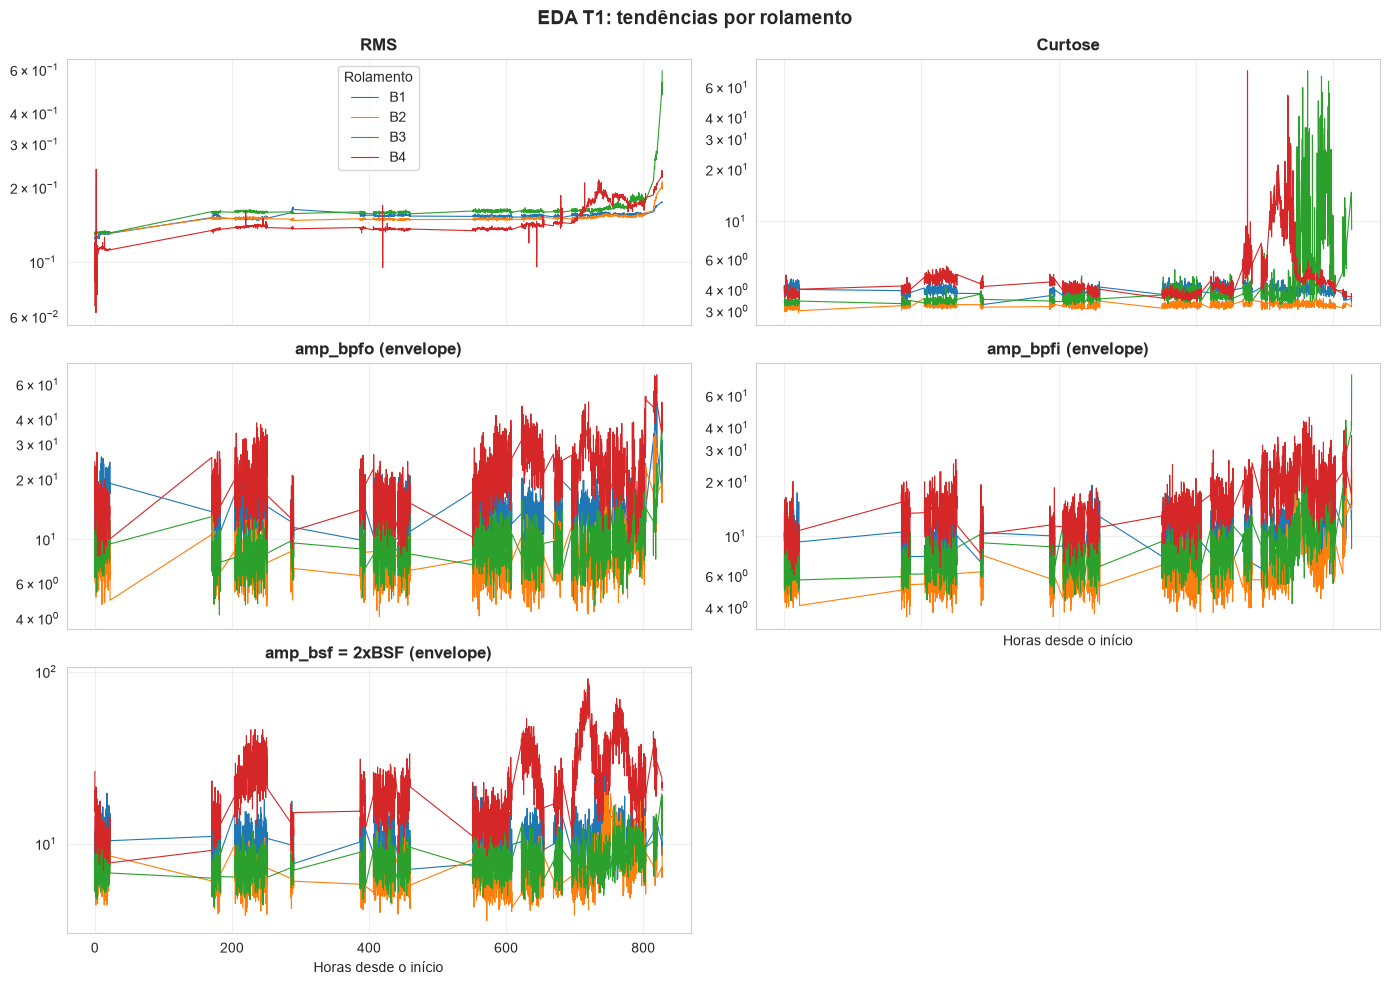

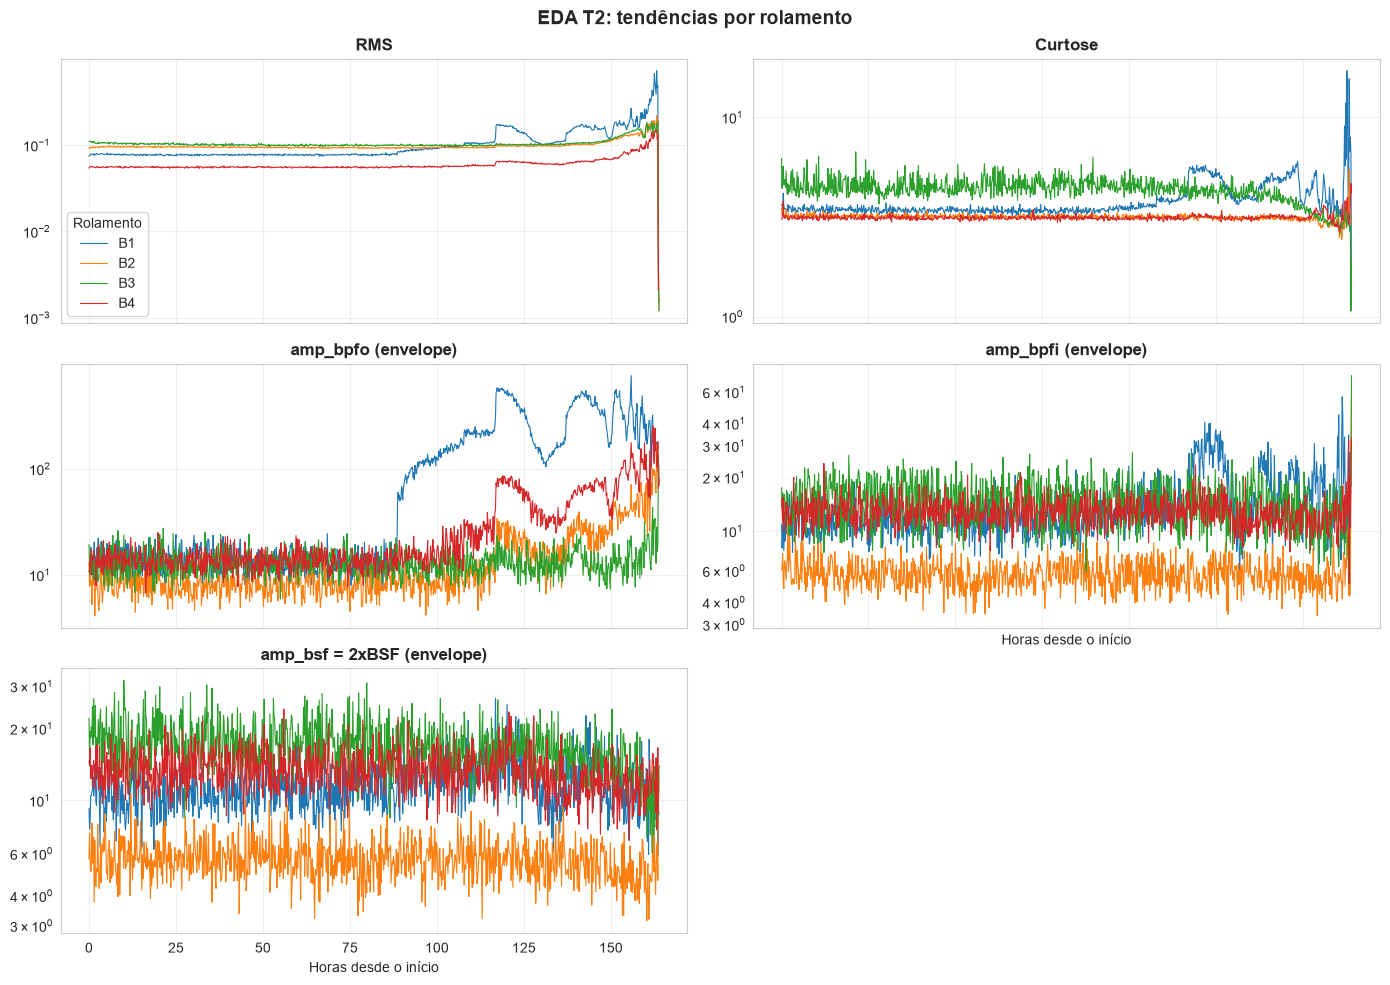

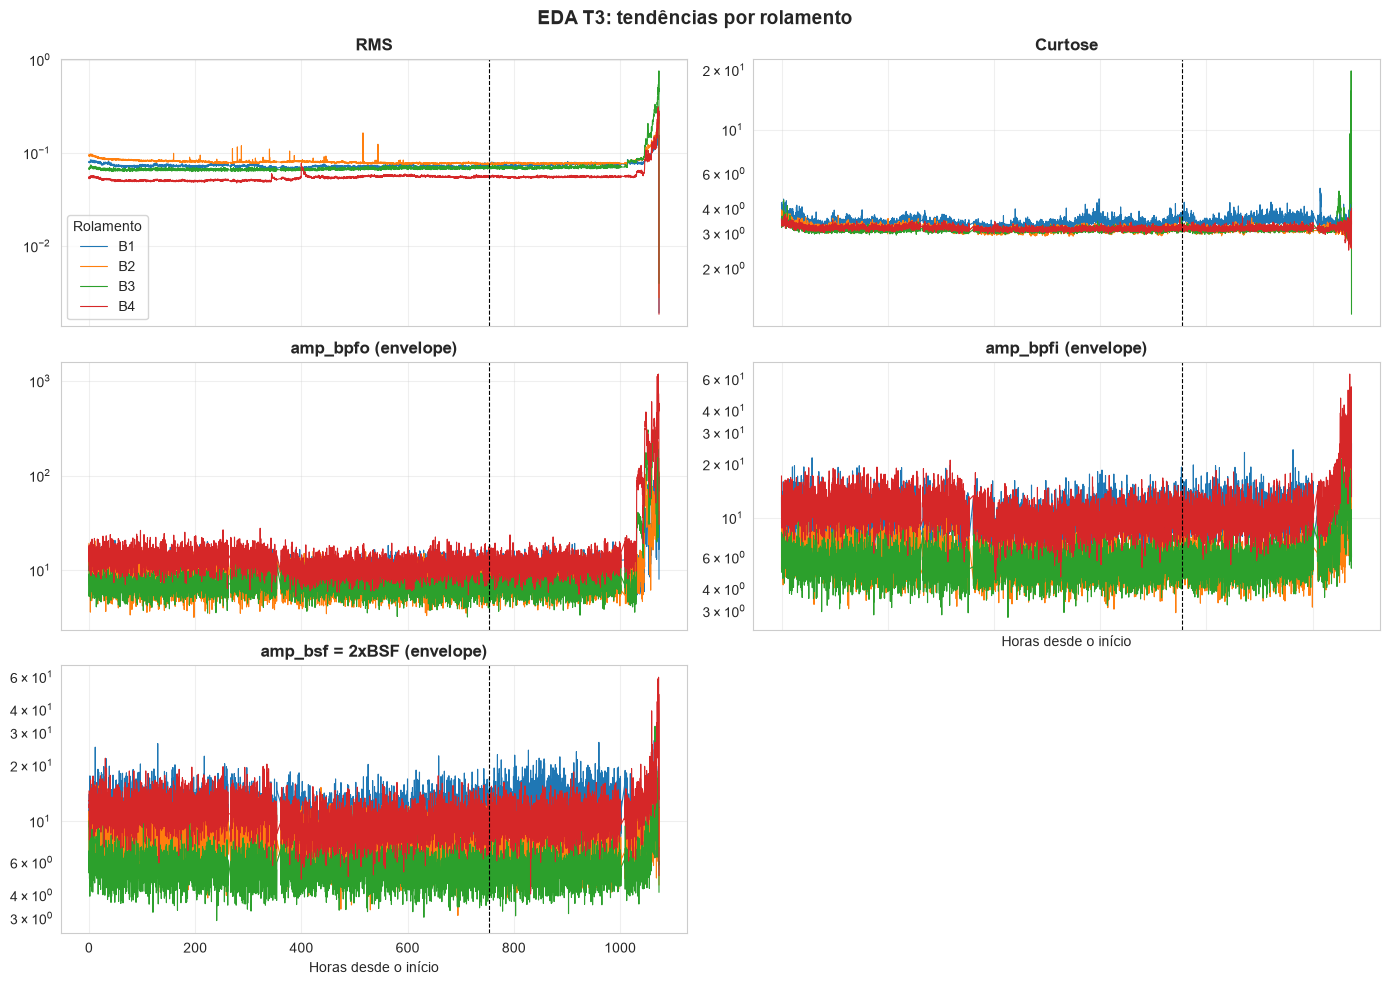

In [6]:
df_plot = df.copy()
for ensaio in ['T1', 'T2', 'T3']:
    figuras_eda.fig_tendencias(df_plot, ensaio)

Sinal bruto e espectro do envelope no início e no fim da vida dos 4 rolamentos que falharam (sinais do cache da CNN).

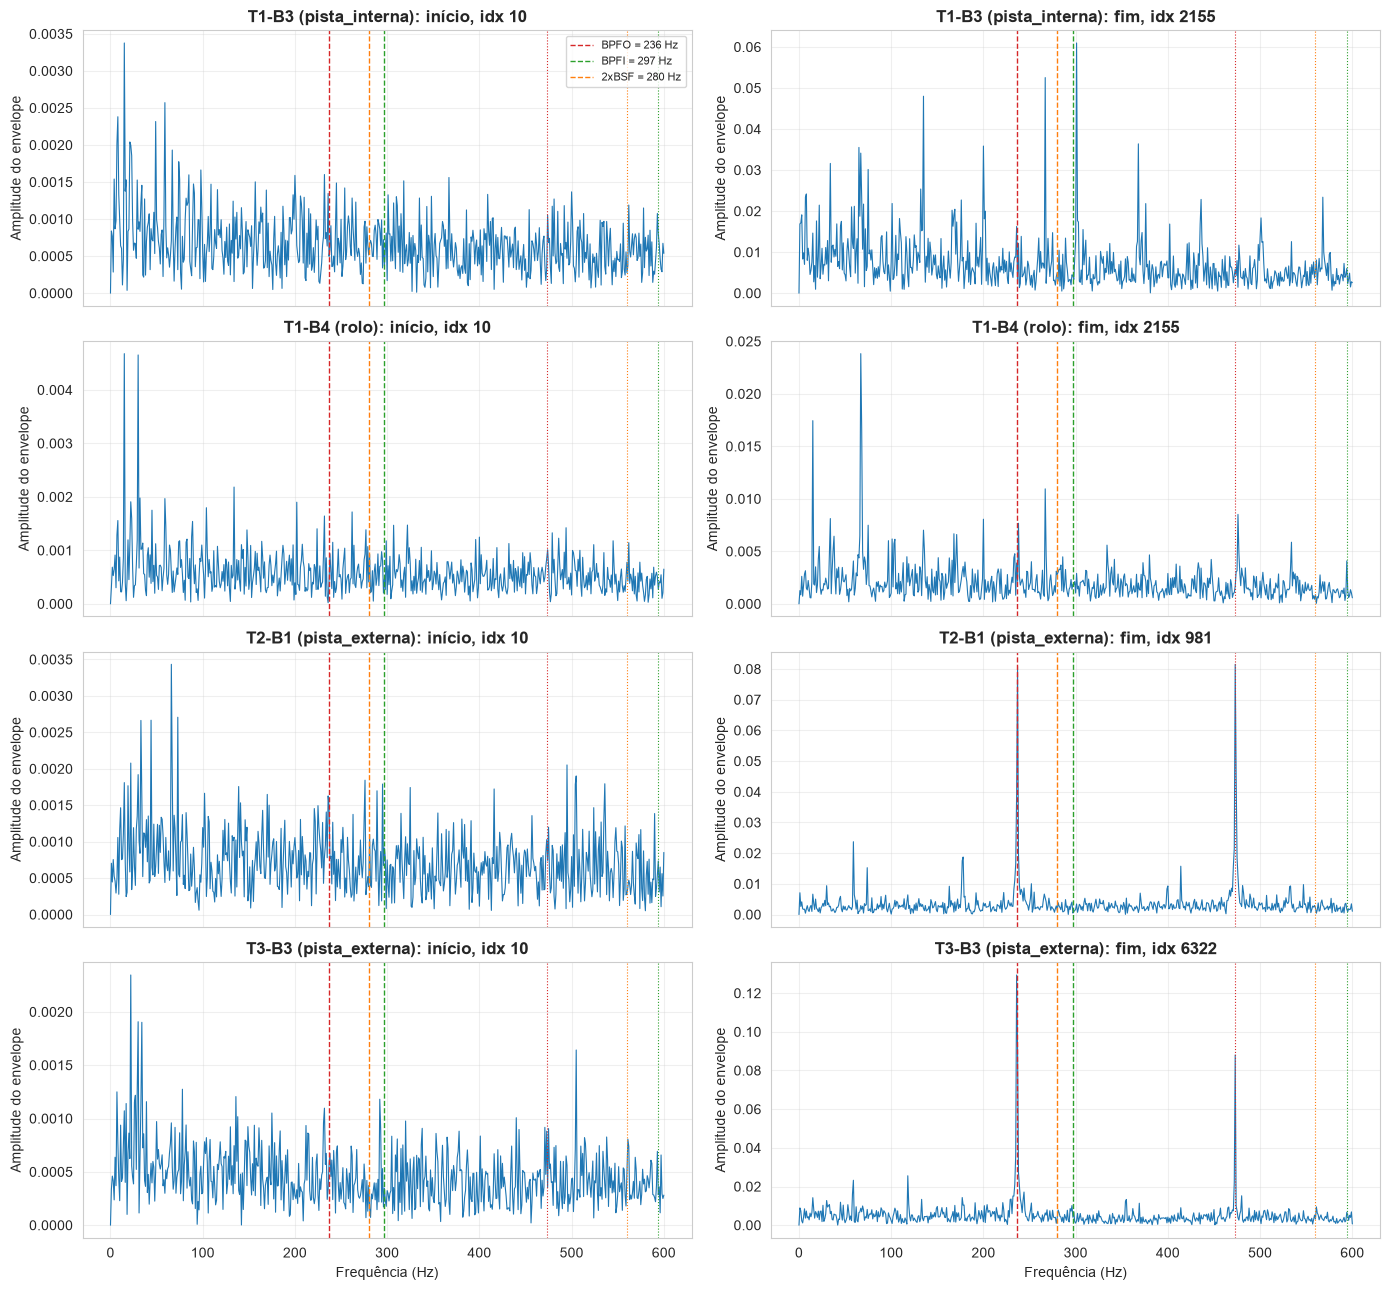

In [7]:
sinais, meta = cnn.carregar_cache()
pos_snap = pd.Series(np.arange(len(meta)), index=meta['snapshot_id'])


def sinal_de(snapshot_id):
    """Sinal bruto (20480 pontos) de um snapshot do cache."""
    return sinais[pos_snap[snapshot_id]].astype(np.float64)


fig, axs = plt.subplots(4, 2, figsize=(14, 13), sharex=True)
for i, ((ensaio, rol), falha) in enumerate(labels.FALHAS.items()):
    m = meta[(meta['ensaio'] == ensaio) & (meta['rolamento'] == rol)].sort_values('idx')
    for j, linha in enumerate([m.iloc[0], m.iloc[-1]]):
        f, esp = features.espectro_envelope(sinal_de(linha['snapshot_id']), FS)
        rot = 'início' if j == 0 else 'fim'
        graficos.espectro_envelope_painel(axs[i, j], f, esp, FREQS,
                                          f'{ensaio}-{rol} ({falha}): {rot}, idx {linha["idx"]}')
axs[0, 0].legend(fontsize=8)
for ax in axs[-1]:
    ax.set_xlabel('Frequência (Hz)')
plt.tight_layout()
graficos.finalizar(FIGURAS / 'eda_envelope_inicio_fim.png', dpi=100)

## 2. Features (1 linha por snapshot)
21 features por snapshot e rolamento (`src/features.py`):
- **tempo:** RMS, pico, pico-a-pico, curtose, assimetria, fatores de crista/forma/impulso, desvio;
- **frequência (FFT):** frequência de pico, centróide espectral, energia em 0–1, 1–3, 3–6 e 6–10 kHz;
- **envelope** (Randall & Antoni 2011): passa-banda Butterworth 1–9 kHz → |Hilbert| → FFT; amplitude em BPFO, BPFI e 2×BSF
  (±3%), normalizada pela mediana do espectro, e a soma do 1º + 2º harmônico (`_h12`).

A extração dos 9.464 arquivos (37.856 linhas) leva ~2 min com 12 núcleos (`src/build_features.py`); por isso fica em cache.
Abaixo, a função do envelope e a conferência de um snapshot recalculado a partir do sinal bruto.

In [8]:
import inspect
print(inspect.getsource(features.features_envelope))

def features_envelope(x, fs, freqs):
    """Amplitudes do espectro do envelope nas frequências de defeito.

    freqs: dict com 'BPFO', 'BPFI', 'BSF' (Hz). Para o rolo usa-se 2xBSF.
    Cada amplitude é normalizada pela mediana do espectro do envelope.
    O sufixo _h12 soma o 1º e o 2º harmônico.
    """
    f, esp = espectro_envelope(x, fs)
    ref = np.median(esp[f > 0])                    # nível de ruído de fundo
    alvos = {'bpfo': freqs['BPFO'], 'bpfi': freqs['BPFI'], 'bsf': 2 * freqs['BSF']}
    saida = {}
    for nome, f0 in alvos.items():
        a1 = amp_na_faixa(f, esp, f0) / ref
        a2 = amp_na_faixa(f, esp, 2 * f0) / ref
        saida[f'amp_{nome}'] = a1
        saida[f'amp_{nome}_h12'] = a1 + a2
    return saida



In [9]:
# Conferência: recalcula as features de um snapshot (sinal do cache, float16) e compara com o parquet
sid = meta.loc[(meta['ensaio'] == 'T2') & (meta['classe'] == 'pista_externa'), 'snapshot_id'].iloc[-1]
recalc = pd.Series(features.features_snapshot(sinal_de(sid), FS, FREQS))
salvo = df.set_index('snapshot_id').loc[sid, COLS_FEATURES]
comparacao = pd.DataFrame({'parquet': salvo.astype(float), 'recalculado': recalc[COLS_FEATURES]})
comparacao['dif_rel_%'] = 100 * (comparacao['recalculado'] / comparacao['parquet'] - 1)
print(sid)
print(comparacao.round(4))

T2_1_2004.02.19.06.02.39
                       parquet  recalculado  dif_rel_%
rms                     0.4838       0.4838     0.0002
pico                    3.6960       3.6953    -0.0186
pico_a_pico             7.1970       7.1973     0.0037
curtose                 7.8918       7.8919     0.0014
assimetria             -0.3771      -0.3771    -0.0095
fator_crista            7.6390       7.6375    -0.0188
fator_forma             1.3781       1.3781     0.0002
fator_impulso          10.5271      10.5251    -0.0186
desvio                  0.4838       0.4838     0.0002
frequencia_pico      4963.0000    4963.0000     0.0000
centroide_espectral  4022.9154    4022.9238     0.0002
energia_0_1k            0.0125       0.0125    -0.0014
energia_1_3k            0.0296       0.0296    -0.0005
energia_3_6k            0.0652       0.0652     0.0012
energia_6_10k           0.0095       0.0095     0.0004
amp_bpfo              120.0984     120.0786    -0.0165
amp_bpfo_h12          241.2488     241.2

In [10]:
df[COLS_FEATURES].describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
rms,37856.0,0.0917,0.0402,0.0012,0.0671,0.0763,0.1102,0.7588
pico,37856.0,0.4678,0.2885,0.0020,0.3080,0.3910,0.5540,5.0000
pico_a_pico,37856.0,0.8325,0.4720,0.0040,0.5860,0.7300,0.9230,9.9980
curtose,37856.0,3.5238,1.6886,1.0646,3.1360,3.2335,3.4884,74.5618
assimetria,37856.0,0.0250,0.0816,-2.5424,-0.0118,0.0175,0.0577,2.1570
fator_crista,37856.0,5.0474,1.1596,1.6146,4.4444,4.8271,5.3328,25.9487
fator_forma,37856.0,1.2474,0.0343,1.0353,1.2495,1.2583,1.2637,1.6716
fator_impulso,37856.0,6.3083,1.5192,1.8759,5.5347,6.0395,6.7064,33.1359
desvio,37856.0,0.0797,0.0261,0.0010,0.0669,0.0755,0.0914,0.7570
frequencia_pico,37856.0,1019.9165,453.2430,1.0000,1009.0000,1009.0000,1010.0000,9279.0000


## 3. Rotulagem: início da falha (μ+3σ) + PCA/KMeans + literatura
O IMS não tem rótulo por snapshot, só a falha no fim do ensaio. Definimos o **início da falha** de cada rolamento com:
1. **Regra estatística:** 3 indicadores (log RMS, curtose, envelope na frequência do defeito) acima de μ+3σ
   (baseline = 10–40% da vida) por 10 snapshots seguidos; início = quando **2 de 3** cruzaram (cf. Rehab et al. 2021).
2. **Validação com PCA + KMeans** (Jolliffe & Cadima 2016; MacQueen 1967), com k escolhido pela silhueta (Rousseeuw 1987),
   e **dendrograma** do agrupamento hierárquico de Ward (Ward 1963).
3. **Literatura:** inícios de degradação reportados por Gousseau et al. (2016), Hasani et al. (2017) e Rehab et al. (2021).

Os inícios adotados estão em `src/labels.py` (`INICIO`, `CORTE_NORMAL`, `rotular`, `split_temporal`) e valem para todo o trabalho.

In [11]:
# Indicador de envelope de cada rolamento que falhou (frequência do seu defeito)
ENVELOPE = {('T1', 'B3'): 'amp_bpfi', ('T1', 'B4'): 'amp_bsf', ('T2', 'B1'): 'amp_bpfo', ('T3', 'B3'): 'amp_bpfo'}


def inicio_3sigma(v, ini, fim, n=10):
    """Primeira posição com n snapshots seguidos acima de mu + 3 sigma (log10; baseline = posições ini:fim)."""
    v = np.log10(v)
    base = v[ini:fim]
    acima = (v > base.mean() + 3 * base.std()).astype(int)
    seguidos = pd.Series(acima).rolling(n).sum().values
    pos = np.where(seguidos >= n)[0]
    return int(pos[0] - n + 1) if len(pos) else None


df_valido = df[df['rms'] > 0.01]                  # descarta snapshots com sinal colapsado
tabela_inicio = []
for (ensaio, rol), col_env in ENVELOPE.items():
    d = df_valido[(df_valido['ensaio'] == ensaio) & (df_valido['rolamento'] == rol)].sort_values('idx').reset_index(drop=True)
    a, b = int(0.1 * len(d)), int(0.4 * len(d))
    cruz = {nome: inicio_3sigma(d[col].values, a, b) for nome, col in [('RMS', 'rms'), ('curtose', 'curtose'), ('envelope', col_env)]}
    cruz = {k: (None if v is None else int(d.loc[v, 'idx'])) for k, v in cruz.items()}
    validos = sorted(v for v in cruz.values() if v is not None)
    tabela_inicio.append({'rolamento': f'{ensaio}-{rol}', **cruz, 'inicio_2de3': validos[1],
                          'inicio_adotado': labels.INICIO[(ensaio, rol)]})
tabela_inicio = pd.DataFrame(tabela_inicio)
print(tabela_inicio.to_string(index=False))
assert (tabela_inicio['inicio_2de3'] == tabela_inicio['inicio_adotado']).all()

rolamento  RMS  curtose  envelope  inicio_2de3  inicio_adotado
    T1-B3 1791     1819    2007.0         1819            1819
    T1-B4 1605     1483       NaN         1605            1605
    T2-B1  532      647     532.0          532             532
    T3-B3 5497       18    6070.0         5497            5497


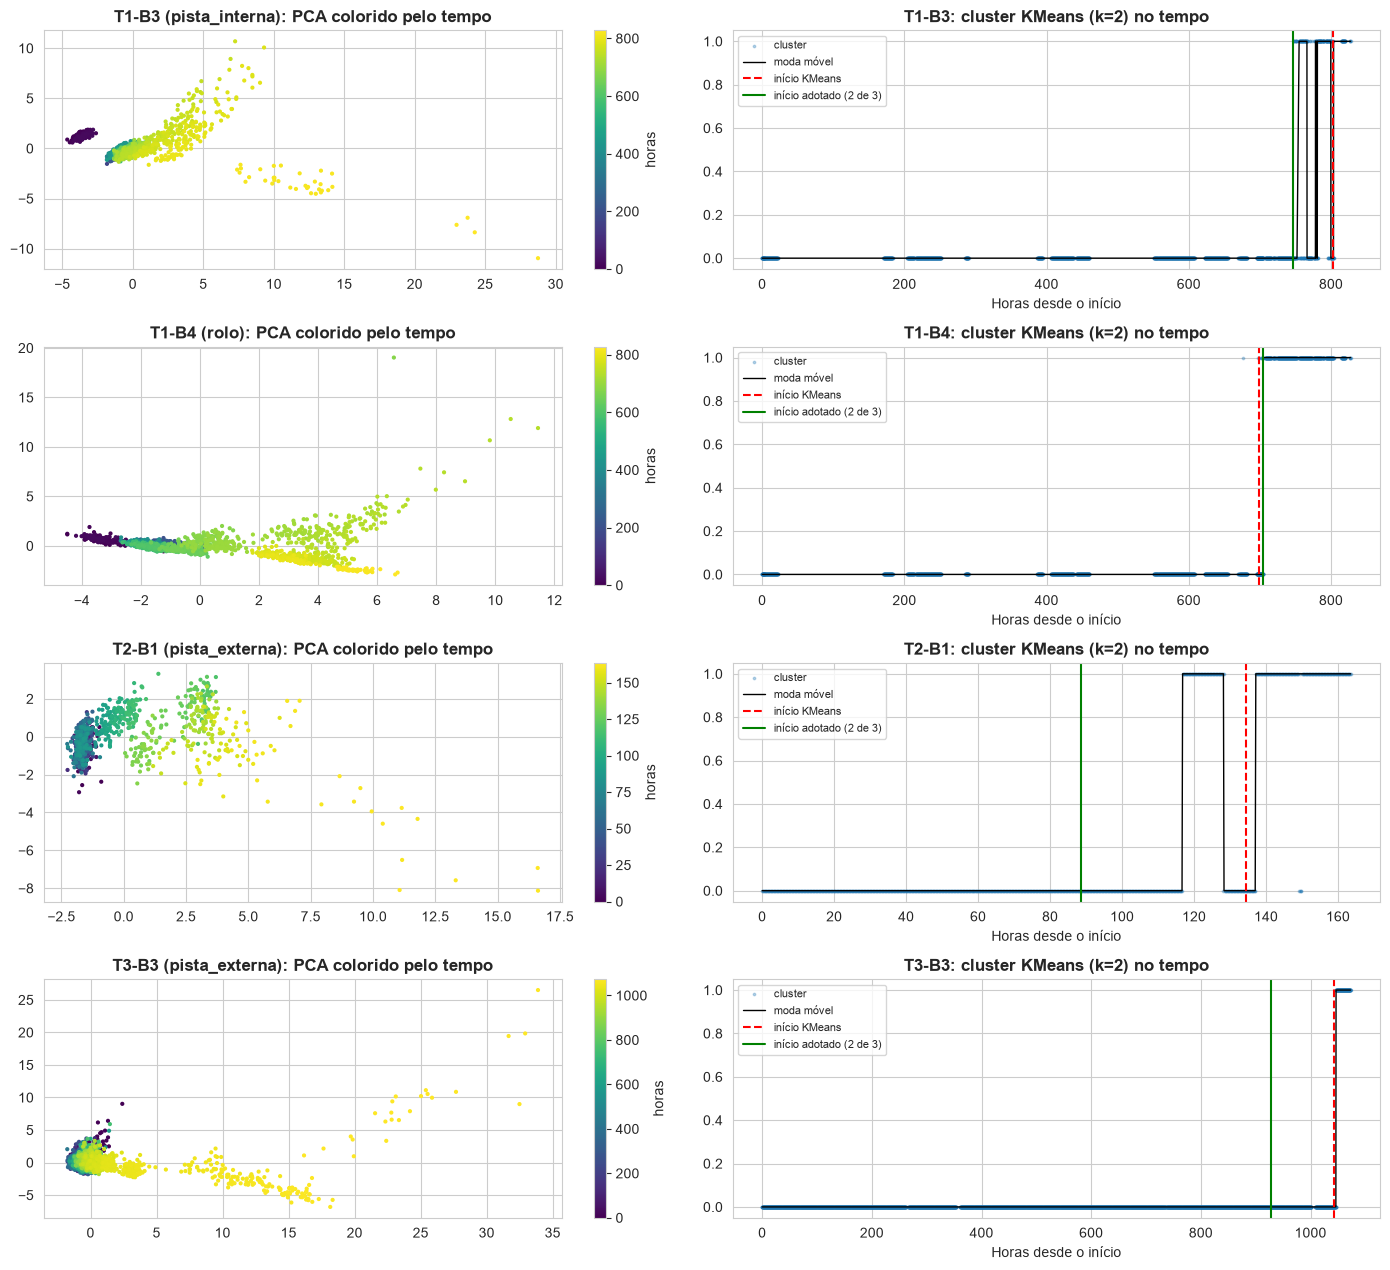

rolamento  k  silhueta  inicio_kmeans_idx  inicio_adotado_idx
    T1-B3  2     0.757               2113                1819
    T1-B4  2     0.703               1550                1605
    T2-B1  2     0.652                806                 532
    T3-B3  2     0.908               6145                5497


In [12]:
# PCA 2D + KMeans (k por silhueta) em cada rolamento que falhou: estágios de degradação
fig, axs = plt.subplots(len(labels.FALHAS), 2, figsize=(14, 3.2 * len(labels.FALHAS)))
tabela_km = []
for i, ((ensaio, rol), falha) in enumerate(labels.FALHAS.items()):
    d = df_valido[(df_valido['ensaio'] == ensaio) & (df_valido['rolamento'] == rol)].sort_values('idx').reset_index(drop=True)
    k, sil, rot, Z = labels.estagios_kmeans(d)
    rot_s = labels.suavizar(rot)
    ini = labels.inicio_persistente(rot_s)
    tabela_km.append({'rolamento': f'{ensaio}-{rol}', 'k': k, 'silhueta': round(sil[k], 3),
                      'inicio_kmeans_idx': int(d.loc[ini, 'idx']), 'inicio_adotado_idx': labels.INICIO[(ensaio, rol)]})
    sc = axs[i, 0].scatter(Z[:, 0], Z[:, 1], c=d['horas_desde_inicio'], s=4, cmap='viridis')
    axs[i, 0].set_title(f'{ensaio}-{rol} ({falha}): PCA colorido pelo tempo', fontsize=12, weight='bold')
    plt.colorbar(sc, ax=axs[i, 0], label='horas')
    axs[i, 1].scatter(d['horas_desde_inicio'], rot, s=3, alpha=0.3, label='cluster')
    axs[i, 1].plot(d['horas_desde_inicio'], rot_s, color='k', lw=1, label='moda móvel')
    axs[i, 1].axvline(d.loc[ini, 'horas_desde_inicio'], color='r', ls='--', label='início KMeans')
    h_adot = d.loc[d['idx'] >= labels.INICIO[(ensaio, rol)], 'horas_desde_inicio'].iloc[0]
    axs[i, 1].axvline(h_adot, color='g', ls='-', label='início adotado (2 de 3)')
    axs[i, 1].set_title(f'{ensaio}-{rol}: cluster KMeans (k={k}) no tempo', fontsize=12, weight='bold')
    axs[i, 1].set_xlabel('Horas desde o início')
    axs[i, 1].legend(fontsize=8)
plt.tight_layout()
graficos.finalizar(FIGURAS / 'rotulagem_estagios.png', dpi=100)
print(pd.DataFrame(tabela_km).to_string(index=False))

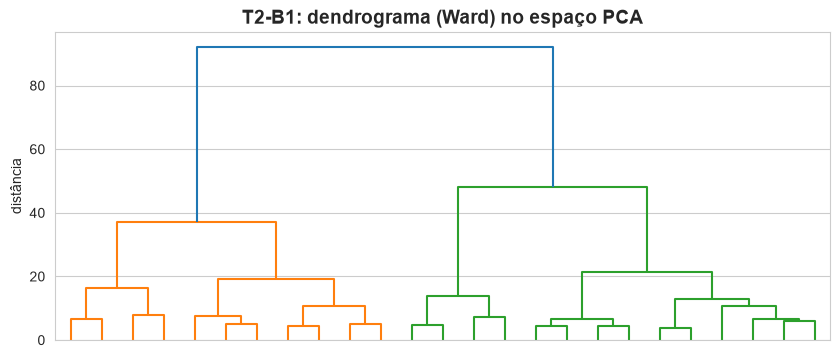

In [13]:
# Dendrograma (Ward) do T2-B1 no espaço PCA 2D: 2 grupos bem separados = saudável x degradado
d = df_valido[(df_valido['ensaio'] == 'T2') & (df_valido['rolamento'] == 'B1')].sort_values('idx')
Z_t2 = Pipeline([('scaler', StandardScaler()), ('pca', PCA(n_components=2))]).fit_transform(labels.matriz_cluster(d))
plt.figure(figsize=(10, 4))
dendrogram(linkage(Z_t2, method='ward'), truncate_mode='lastp', p=25, no_labels=True)
plt.title('T2-B1: dendrograma (Ward) no espaço PCA', fontsize=14, weight='bold')
plt.ylabel('distância')
graficos.finalizar(FIGURAS / 'rotulagem_dendrograma_T2B1.png', dpi=100)

**Comparação com a literatura** (Gousseau et al. 2016; Hasani et al. 2017; Rehab et al. 2021; Mousaei Shir-Mohammad et al. 2026):
T1-B3 início 1819 (literatura 1570–2120); T1-B4 1605 (745–1760); T2-B1 532 (505–547); T3-B3 5497 (5565–6092).
Os inícios adotados caem dentro das faixas publicadas, exceto no T3-B3, em que a regra 2 de 3 marca a degradação um pouco
antes. O KMeans, dominado pelo RMS, marca o início mais tarde.

**Classes:** *Normal* = todos os rolamentos antes do corte do ensaio (menor início do ensaio − 5% da vida; o defeito
contamina os vizinhos do mesmo eixo) sem os 10 primeiros snapshots (amaciamento); *falhas* = a partir do início adotado;
a zona de transição fica **excluída**. Split temporal 70/30 por (ensaio, rolamento, classe).

In [14]:
# Rótulos e split temporal (src/labels.py) e checagem contra o arquivo salvo
rotulado = labels.split_temporal(labels.rotular(df))
salvo = pd.read_parquet(dados_cache.ROTULADO)
pd.testing.assert_frame_equal(rotulado.reset_index(drop=True), salvo.reset_index(drop=True), check_dtype=False)
treino_ids = set(rotulado.loc[rotulado['conjunto'] == 'treino', 'snapshot_id'])
teste_ids = set(rotulado.loc[rotulado['conjunto'] == 'teste', 'snapshot_id'])
assert not treino_ids & teste_ids, 'vazamento: snapshot em treino e teste'
print('excluídos (transição, sadios após o corte, colapsados):', len(df) - len(rotulado))
rotulado.groupby(['classe', 'conjunto']).size().unstack()

excluídos (transição, sadios após o corte, colapsados): 7656


conjunto,teste,treino
classe,,
normal,8404,19632
pista_externa,382,894
pista_interna,101,236
rolo,165,386


## 4. Detecção de anomalias (Normal × Falha)
Três detectores de complexidade crescente, do limiar estatístico ao classificador supervisionado. D1 e D2 só veem o
**Normal do treino** (detecção de novidade: não precisam de exemplos de falha).
- **D1** — limiar estatístico μ+3σ de log(RMS) e curtose (Randall 2011): alarme se qualquer z > 3.
- **D2** — `StandardScaler` + PCA (90% da variância) + KMeans (k por silhueta) no Normal; score = distância ao centróide
  mais próximo; limiar = percentil 99 do Normal do treino (Jolliffe & Cadima 2016; MacQueen 1967).
- **D3** — classificadores binários supervisionados (LogisticRegression e Random Forest) com `predict_proba`; limiar de
  decisão no ponto de Youden da curva ROC (Youden 1950), escolhido na CV do treino (`cross_val_predict`).

Métricas no teste: TPR, FPR, AUC; na vida completa: **antecedência** (1º alarme com 10 snapshots seguidos) e alarmes falsos nos sadios.

In [15]:
# Entradas e Saídas
treino, teste = classic.carregar_dataset()
X_tr, X_te = matriz_X(treino), matriz_X(teste)            # 21 features, log10 em amplitudes/energias
yb_tr, yb_te = detect.alvo_binario(treino), detect.alvo_binario(teste)
X_normal = X_tr[yb_tr == 0]
cv = classic.validacao_cruzada()                          # StratifiedKFold(5, shuffle=False)
print('treino:', X_tr.shape, '| teste:', X_te.shape, '| Normal do treino:', X_normal.shape)
t_det = time.time()

treino: (21148, 21) | teste: (9052, 21) | Normal do treino: (19632, 21)


In [16]:
# ---------------- D1: limiar mu + 3 sigma ----------------
# Treinamento: média e desvio de log10(RMS) e curtose no Normal do treino
params_d1 = {c: (X_normal[c].mean(), X_normal[c].std()) for c in ['rms', 'curtose']}


def score_d1(X):
    """Maior z-score entre log10(RMS) e curtose (alarme se > 3)."""
    z = [(X[c] - mu) / sd for c, (mu, sd) in params_d1.items()]
    return np.maximum(*z).values


print({c: (round(m, 3), round(s, 3)) for c, (m, s) in params_d1.items()})

{'rms': (np.float64(-1.101), np.float64(0.148)), 'curtose': (np.float64(3.346), np.float64(0.355))}


D2: 6 componentes PCA, k = 9, limiar (p99) = 4.199


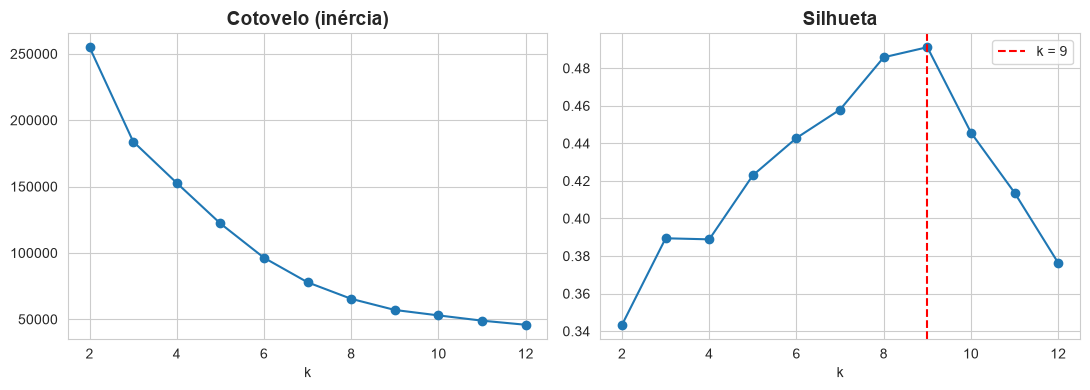

In [17]:
# ---------------- D2: PCA + KMeans só no Normal ----------------
# Definição
pipe_d2 = Pipeline([('scaler', StandardScaler()), ('pca', PCA(n_components=0.9, random_state=RANDOM_STATE))])
# Treinamento
Z_normal = pipe_d2.fit_transform(X_normal)
inercias, silhuetas = {}, {}
for k in range(2, 13):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z_normal)
    inercias[k] = km.inertia_
    silhuetas[k] = silhouette_score(Z_normal, km.labels_, sample_size=5000, random_state=RANDOM_STATE)
k_d2 = max(silhuetas, key=silhuetas.get)
kmeans_d2 = KMeans(n_clusters=k_d2, n_init=10, random_state=RANDOM_STATE).fit(Z_normal)


def score_d2(X):
    """Distância ao centróide mais próximo no espaço PCA."""
    return kmeans_d2.transform(pipe_d2.transform(X)).min(axis=1)


limiar_d2 = float(np.percentile(score_d2(X_normal), 99))
n_comp_d2 = int(pipe_d2.named_steps['pca'].n_components_)
print(f'D2: {n_comp_d2} componentes PCA, k = {k_d2}, limiar (p99) = {limiar_d2:.3f}')

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(list(inercias), list(inercias.values()), 'o-')
axs[0].set_title('Cotovelo (inércia)', fontsize=14, weight='bold')
axs[1].plot(list(silhuetas), list(silhuetas.values()), 'o-')
axs[1].axvline(k_d2, color='r', ls='--', label=f'k = {k_d2}')
axs[1].set_title('Silhueta', fontsize=14, weight='bold')
axs[1].legend()
for ax in axs:
    ax.set_xlabel('k')
plt.tight_layout()
graficos.finalizar(FIGURAS / 'deteccao_d2_escolha_k.png', dpi=100)

In [18]:
# ---------------- D3: classificadores binários + limiar de Youden ----------------
# Definição
modelos_d3 = {
    'D3_LogReg': Pipeline([('scaler', StandardScaler()),
                           ('classifier', LogisticRegression(class_weight='balanced', max_iter=2000,
                                                             random_state=RANDOM_STATE))]),
    'D3_RF': Pipeline([('scaler', 'passthrough'),
                       ('classifier', RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                                             random_state=RANDOM_STATE, n_jobs=-1))]),
}
# Treinamento: limiar escolhido no treino (probabilidades fora-da-amostra da CV), depois ajuste no treino inteiro
d3 = {}
for nome, modelo in modelos_d3.items():
    prob_oof = cross_val_predict(modelo, X_tr, yb_tr, cv=cv, method='predict_proba')[:, 1]
    fpr_c, tpr_c, thr_c = roc_curve(yb_tr, prob_oof)
    i = np.argmax(tpr_c - fpr_c)                          # índice J de Youden
    modelo.fit(X_tr, yb_tr)
    d3[nome] = {'modelo': modelo, 'limiar': float(thr_c[i]), 'TPR_cv': float(tpr_c[i]), 'FPR_cv': float(fpr_c[i])}
    print(f'{nome}: limiar Youden = {thr_c[i]:.3f}  (CV: TPR={tpr_c[i]:.3f}, FPR={fpr_c[i]:.3f})')

D3_LogReg: limiar Youden = 0.339  (CV: TPR=0.967, FPR=0.381)


D3_RF: limiar Youden = 0.305  (CV: TPR=0.816, FPR=0.081)


             TPR    FPR    AUC  TPR pista_externa  TPR pista_interna  TPR rolo
D1         0.461  0.016  0.933              0.424              0.812     0.333
D2         0.935  0.013  0.997              0.945              0.970     0.891
D3_LogReg  0.940  0.211  0.972              1.000              1.000     0.764
D3_RF      0.994  0.053  0.991              0.990              1.000     1.000


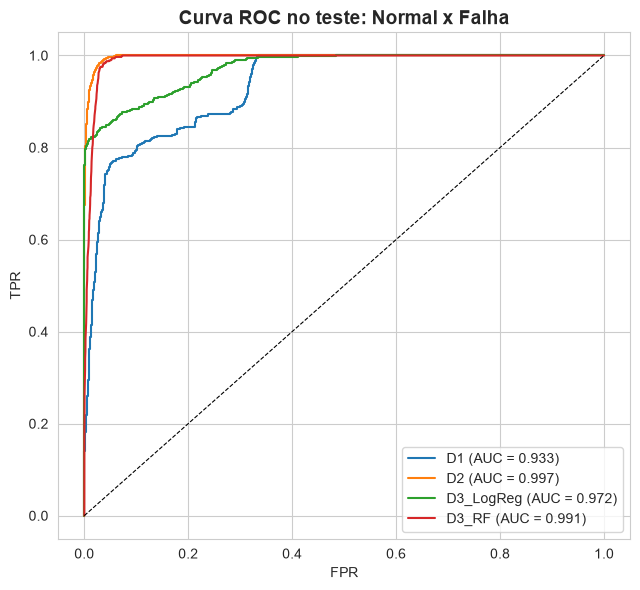

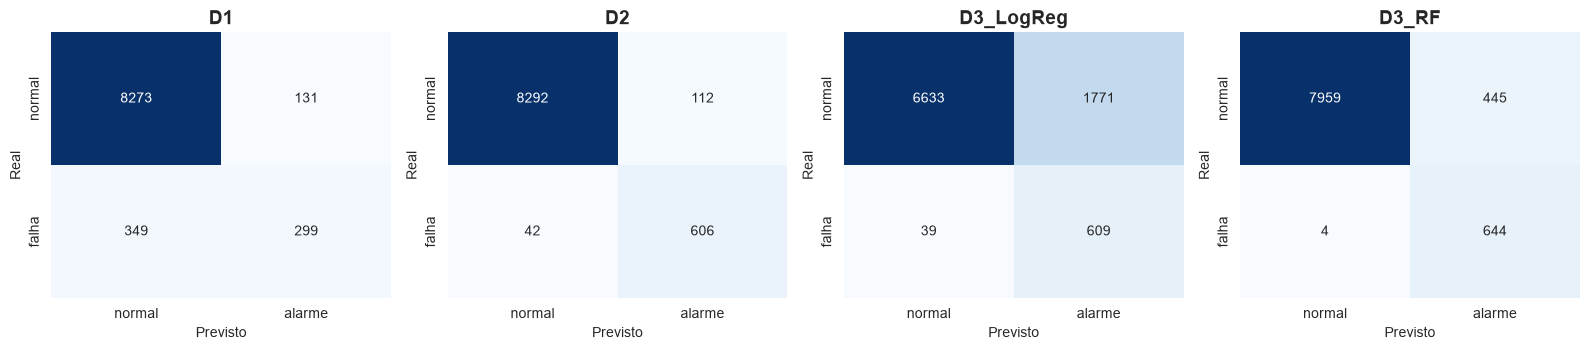

In [19]:
# Avaliação no teste
detectores = {'D1': (score_d1, 3.0), 'D2': (score_d2, limiar_d2)}
for nome, r in d3.items():
    detectores[nome] = (lambda X, m=r['modelo']: m.predict_proba(X)[:, 1], r['limiar'])

scores_te = {nome: f(X_te) for nome, (f, _) in detectores.items()}
met_det = {nome: detect.metricas_binarias(yb_te, scores_te[nome], lim) for nome, (_, lim) in detectores.items()}
tpr_tipo = {nome: {c: float((scores_te[nome][teste['classe'] == c] > lim).mean())
                   for c in ['pista_externa', 'pista_interna', 'rolo']}
            for nome, (_, lim) in detectores.items()}
tab_det = pd.DataFrame({n: {'TPR': m['TPR'], 'FPR': m['FPR'], 'AUC': m['AUC'], **{f'TPR {c}': v for c, v in tpr_tipo[n].items()}}
                        for n, m in met_det.items()}).T
print(tab_det.round(3))
detect.figura_roc(yb_te, scores_te)
detect.figura_matrizes_2x2(met_det)

**Antecedência e alarmes falsos na vida completa** (D1 e D2): primeiro alarme persistente nos 4 rolamentos que falharam e
fração de snapshots em alarme nos 8 rolamentos sadios, antes e depois do corte do Normal.

      início rotulado (h antes do fim) D1 (h antes do fim) D1 antes do corte?  \
T1-B3                             81.4                81.4              False   
T1-B4                            123.7               605.1               True   
T2-B1                             75.2                46.8              False   
T3-B3                            144.7                10.7              False   

      D2 (h antes do fim)  
T1-B3                81.4  
T1-B4               155.1  
T2-B1                74.2  
T3-B3                42.2  
   antes_corte_total antes_corte_so_teste depois_corte
D1          0.013783             0.017815     0.032074
D2          0.009155             0.007465     0.110871


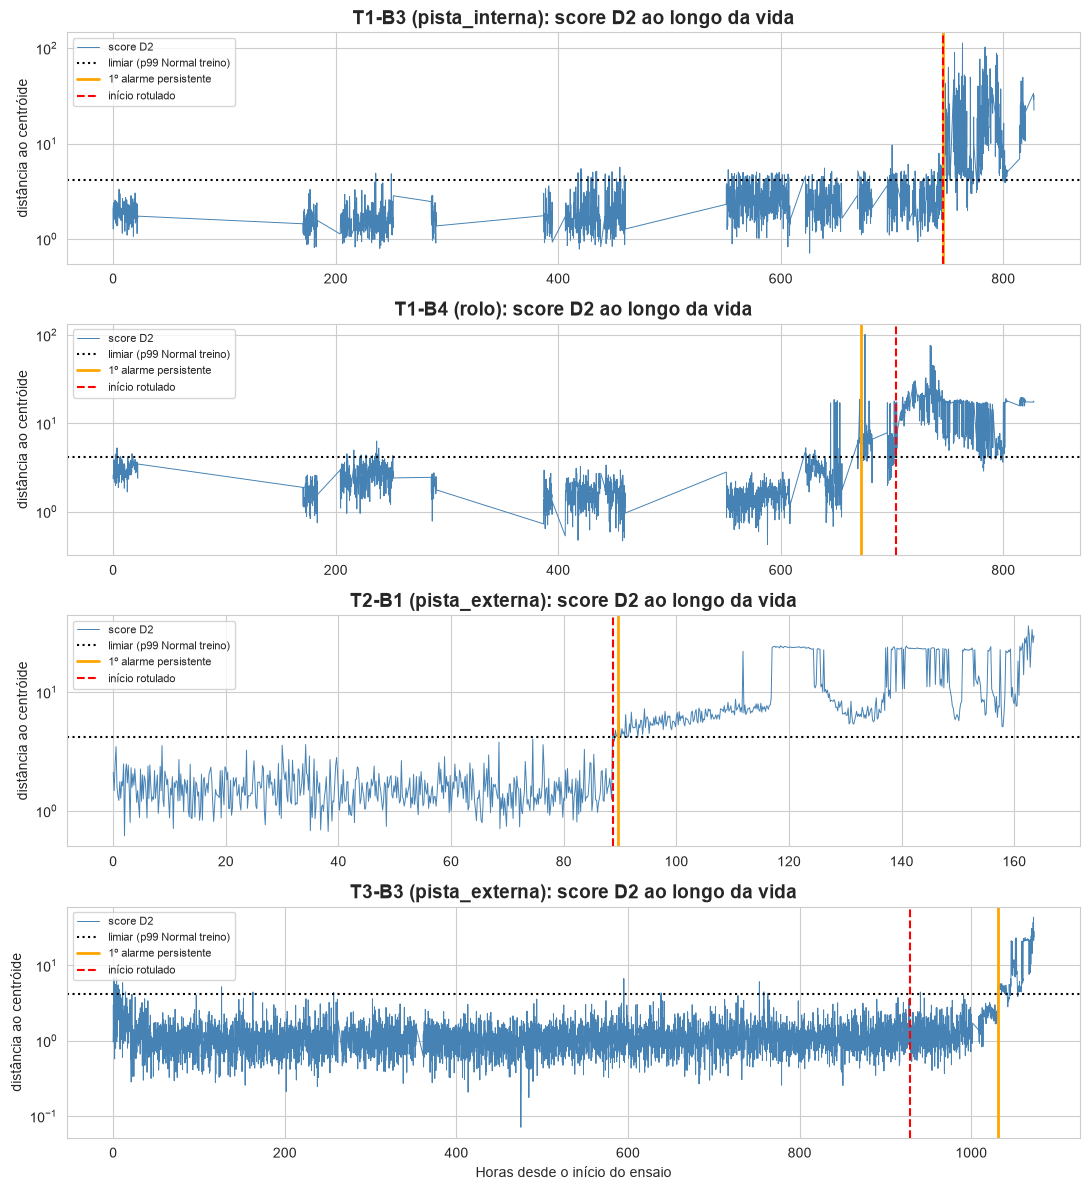

In [20]:
vida = detect.carregar_vida()
nao_sup = {k: detectores[k] for k in ['D1', 'D2']}
antecedencia = detect.antecedencia(vida, nao_sup)
falsos = detect.alarmes_falsos(vida, nao_sup, teste_ids)
tab_ant = pd.DataFrame({r: {'início rotulado (h antes do fim)': v['inicio_rotulado_h_antes_fim'],
                            'D1 (h antes do fim)': v['D1']['h_antes_fim'] if v['D1'] else None,
                            'D1 antes do corte?': v['D1']['antes_do_corte_normal'] if v['D1'] else None,
                            'D2 (h antes do fim)': v['D2']['h_antes_fim'] if v['D2'] else None}
                        for r, v in antecedencia.items()}).T
print(tab_ant)
print(pd.DataFrame(falsos).T[['antes_corte_total', 'antes_corte_so_teste', 'depois_corte']].round(4))
detect.figura_score_d2(vida, {'pipe': pipe_d2, 'kmeans': kmeans_d2, 'limiar': limiar_d2}, antecedencia)

In [21]:
res_deteccao = {
    'D1': {'mu_sigma': {c: [float(m), float(s)] for c, (m, s) in params_d1.items()},
           'obs': 'rms em log10; alarme se z(log RMS) > 3 ou z(curtose) > 3'},
    'D2': {'k': k_d2, 'n_componentes_pca': n_comp_d2, 'limiar_p99': limiar_d2,
           'silhuetas': silhuetas, 'inercias': inercias},
    'D3': {n: {'limiar_youden': r['limiar'], 'TPR_cv': r['TPR_cv'], 'FPR_cv': r['FPR_cv']} for n, r in d3.items()},
    'teste': met_det, 'TPR_por_tipo_teste': tpr_tipo,
    'antecedencia': antecedencia, 'alarmes_falsos_sadios': falsos,
    'tempo_total_s': time.time() - t_det,
}
classic.salvar_json(res_deteccao, RESULTADOS / 'deteccao.json')
TEMPOS['4. detecção'] = res_deteccao['tempo_total_s']
print(f'[tempo] 4. detecção: {TEMPOS["4. detecção"]:.1f} s')

[tempo] 4. detecção: 25.8 s


**Análise.** O D2 tem o melhor compromisso (AUC ≈ 0,997, FPR ≈ 1,3%) e alarma antes ou junto do início rotulado em
3 dos 4 rolamentos. O D1 com baseline global falha porque cada rolamento tem um nível basal diferente (T1-B4 tem curtose
basal acima do limiar → alarme falso 605 h antes do fim). O teste contém o estágio mais severo (30% finais), por isso a AUC
alta não mede detecção precoce — quem mede é a antecedência.

## 5. Diagnóstico multiclasse
### 5.1 Técnica 1 — classificadores sobre as features
Random Forest (Breiman 2001; Qin et al. 2017) e SVC (Cortes & Vapnik 1995; Widodo & Yang 2007) são os destaques;
KNN e Árvore entram na comparação. Cada modelo é um `Pipeline(scaler, classifier)` num `GridSearchCV` com F1 macro
e a validação cruzada temporal (blocos contíguos no tempo). `class_weight='balanced'` compensa o desbalanceamento (92% Normal).
O modelo final é escolhido pela **CV**, não pelo teste.

In [22]:
# Entradas e Saídas
y_tr, y_te = treino['classe'], teste['classe']
print(y_tr.value_counts().to_string())

# Definição (listas base_estimators + param_grids para a comparação de modelos com GridSearchCV)
base_estimators = [
    ('KNN', KNeighborsClassifier()),
    ('Árvore', DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE)),
    ('RandomForest', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=1)),
    ('SVC', SVC(class_weight='balanced', random_state=RANDOM_STATE)),
]
param_grids = [
    {'scaler': [StandardScaler(), 'passthrough'],
     'classifier__n_neighbors': [5, 15], 'classifier__weights': ['uniform', 'distance']},
    {'scaler': ['passthrough'],
     'classifier__max_depth': [5, 10, None], 'classifier__min_samples_leaf': [1, 10]},
    {'scaler': ['passthrough'],
     'classifier__n_estimators': [100], 'classifier__max_depth': [10, None],
     'classifier__min_samples_leaf': [1, 5]},
    {'scaler': [StandardScaler()],
     'classifier__C': [1, 10, 100], 'classifier__gamma': ['scale', 0.01]},
]

# Treinamento
t_classico = time.time()
grid = {}
for (nome, estimador), params in zip(base_estimators, param_grids):
    pipe = Pipeline([('scaler', StandardScaler()), ('classifier', estimador)])
    busca = GridSearchCV(pipe, params, scoring='f1_macro', cv=cv, n_jobs=-1)
    t0 = time.time()
    busca.fit(X_tr, y_tr)
    melhores = {k: (type(v).__name__ if not isinstance(v, (str, int, float, type(None))) else v)
                for k, v in busca.best_params_.items()}
    grid[nome] = {'modelo': busca.best_estimator_, 'f1_cv': busca.best_score_, 'params': melhores,
                  'tempo_s': time.time() - t0}
    print(f'{nome:13s} F1 macro CV = {busca.best_score_:.3f}  ({time.time() - t0:.0f} s)  {melhores}')
tempos_classico = {'gridsearch': time.time() - t_classico}
melhor_cv = max(grid, key=lambda n: grid[n]['f1_cv'])
print('melhor pela CV:', melhor_cv)

classe
normal           19632
pista_externa      894
rolo               386
pista_interna      236


KNN           F1 macro CV = 0.760  (17 s)  {'classifier__n_neighbors': 5, 'classifier__weights': 'uniform', 'scaler': 'StandardScaler'}


Árvore        F1 macro CV = 0.814  (3 s)  {'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'scaler': 'passthrough'}


RandomForest  F1 macro CV = 0.894  (26 s)  {'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 100, 'scaler': 'passthrough'}


SVC           F1 macro CV = 0.833  (18 s)  {'classifier__C': 100, 'classifier__gamma': 'scale', 'scaler': 'StandardScaler'}
melhor pela CV: RandomForest


===== KNN =====
               precision    recall  f1-score   support

       normal      0.998     0.981     0.990      8404
pista_externa      0.697     0.843     0.763       382
pista_interna      0.648     0.822     0.725       101
         rolo      0.805     1.000     0.892       165

     accuracy                          0.974      9052
    macro avg      0.787     0.911     0.842      9052
 weighted avg      0.978     0.974     0.975      9052



===== Árvore =====
               precision    recall  f1-score   support

       normal      0.980     0.956     0.968      8404
pista_externa      0.289     0.374     0.326       382
pista_interna      0.367     0.960     0.532       101
         rolo      0.968     0.558     0.708       165

     accuracy                          0.925      9052
    macro avg      0.651     0.712     0.633      9052
 weighted avg      0.944     0.925     0.932      9052



===== RandomForest =====
               precision    recall  f1-score   support

       normal      0.993     0.968     0.980      8404
pista_externa      0.458     0.579     0.511       382
pista_interna      0.399     0.960     0.564       101
         rolo      0.946     0.739     0.830       165

     accuracy                          0.947      9052
    macro avg      0.699     0.812     0.721      9052
 weighted avg      0.963     0.947     0.953      9052



===== SVC =====
               precision    recall  f1-score   support

       normal      0.999     0.910     0.952      8404
pista_externa      0.165     0.385     0.231       382
pista_interna      0.284     0.941     0.436       101
         rolo      0.959     1.000     0.979       165

     accuracy                          0.890      9052
    macro avg      0.602     0.809     0.650      9052
 weighted avg      0.955     0.890     0.917      9052



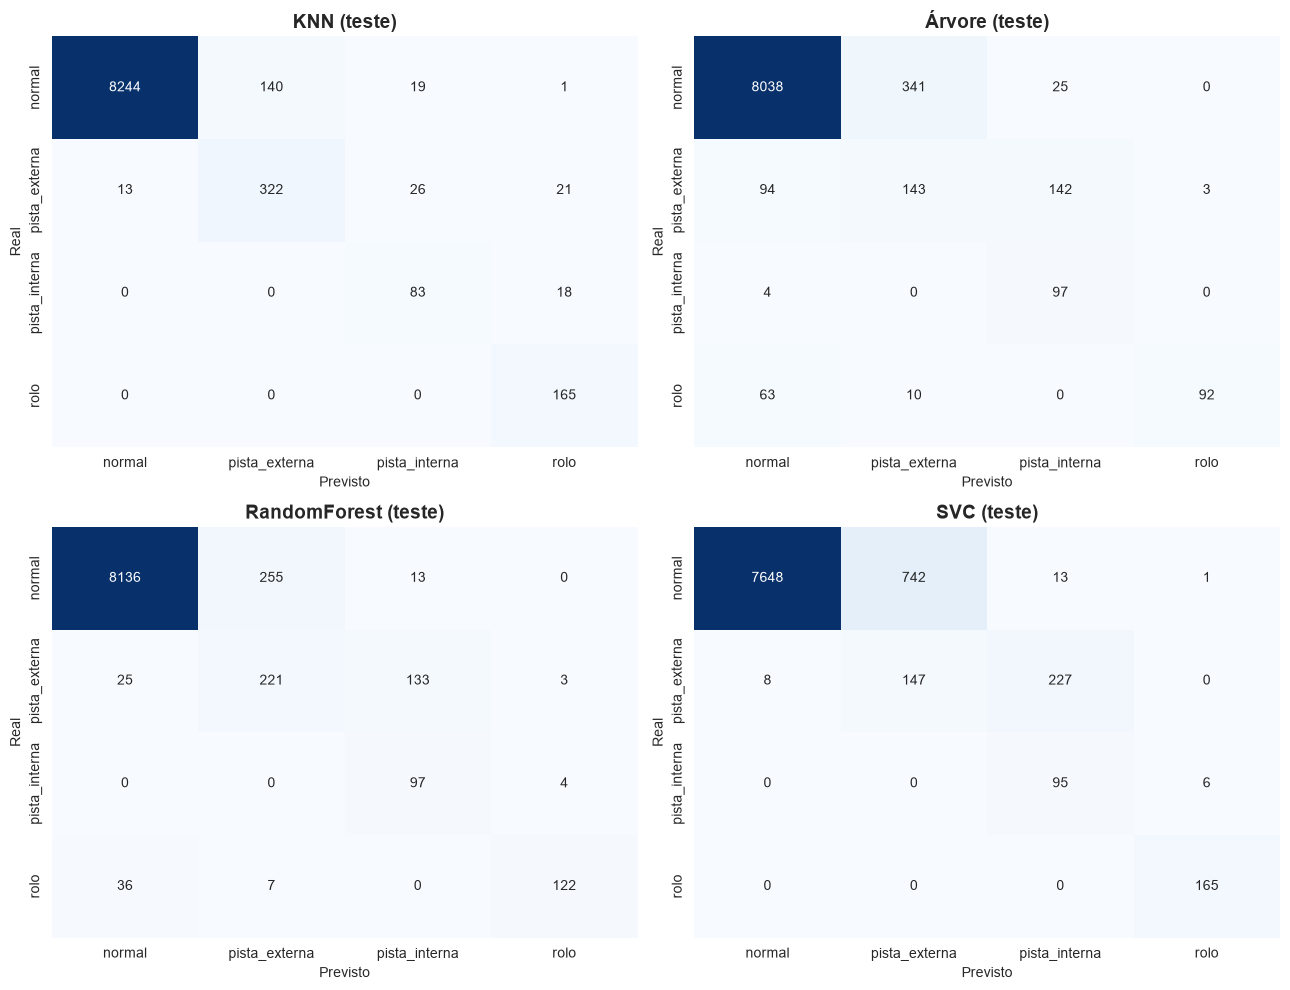

              F1 CV  F1 teste  normal  pista_externa  pista_interna   rolo  \
KNN           0.760     0.842   0.981          0.843          0.822  1.000   
Árvore        0.814     0.633   0.956          0.374          0.960  0.558   
RandomForest  0.894     0.721   0.968          0.578          0.960  0.739   
SVC           0.833     0.650   0.910          0.385          0.941  1.000   

                TPR    FPR  
KNN           0.980  0.019  
Árvore        0.752  0.044  
RandomForest  0.906  0.032  
SVC           0.988  0.090  


In [23]:
# Avaliação no teste: classification_report + matriz de confusão 4x4
avaliacao, pred_te = {}, {}
for nome, r in grid.items():
    pred_te[nome] = r['modelo'].predict(X_te)
    print(f'===== {nome} =====')
    print(classification_report(y_te, pred_te[nome], labels=CLASSES, digits=3, zero_division=0))
    avaliacao[nome] = classic.metricas_multiclasse(y_te, pred_te[nome])
    arq = FIGURAS / f'classico_matriz_{nome.lower().replace("á", "a")}.png'
    classic.figura_matriz_confusao(np.array(avaliacao[nome]['matriz_confusao']), f'Matriz de confusão: {nome}',
                                   arq, mostrar=False)

fig, axs = plt.subplots(2, 2, figsize=(13, 10))
for ax, nome in zip(axs.ravel(), grid):
    graficos.matriz_confusao(avaliacao[nome]['matriz_confusao'], CLASSES, f'{nome} (teste)', ax=ax)
plt.tight_layout()
graficos.finalizar(FIGURAS / 'classico_matrizes.png', dpi=100)

tab_t1 = pd.DataFrame({n: {'F1 CV': grid[n]['f1_cv'], 'F1 teste': a['f1_macro'], **a['acuracia_por_classe'],
                           'TPR': a['TPR_falha'], 'FPR': a['FPR_falha']} for n, a in avaliacao.items()}).T
print(tab_t1.round(3))

In [24]:
# Onde estão os falsos positivos? Fração do Normal de teste prevista como falha, por rolamento
erros_normal = {n: classic.erro_normal_por_rolamento(grid[n]['modelo'], teste, X_te) for n in grid}
pd.DataFrame(erros_normal).round(3)

,KNN,Árvore,RandomForest,SVC
T1-B1,0.000,0.000,0.000,0.000
T1-B2,0.000,0.000,0.000,0.000
T1-B3,0.046,0.061,0.032,0.032
T1-B4,0.002,0.000,0.000,0.002
T2-B1,0.000,0.000,0.000,0.000
T2-B2,0.000,0.000,0.000,0.007
T2-B3,0.000,0.007,0.000,0.000
T2-B4,0.000,0.000,0.000,0.000
T3-B1,0.000,0.000,0.000,0.000
T3-B2,0.000,0.000,0.000,0.001


**Seleção de atributos:** informação mútua (`mutual_info_classif`) e `feature_importances_` do RF (Breiman 2001).
Depois, `SelectKBest(mutual_info, k)` dentro do pipeline, para verificar se um subconjunto menor de features mantém o F1.
A MI é calculada **uma vez por fold**, só com o treino daquele fold (sem vazamento), e reutilizada para todos os valores de k.

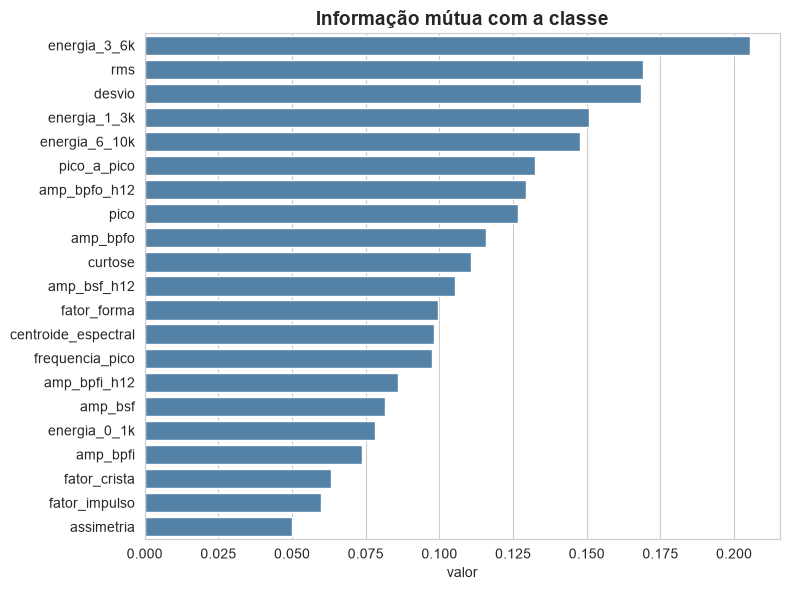

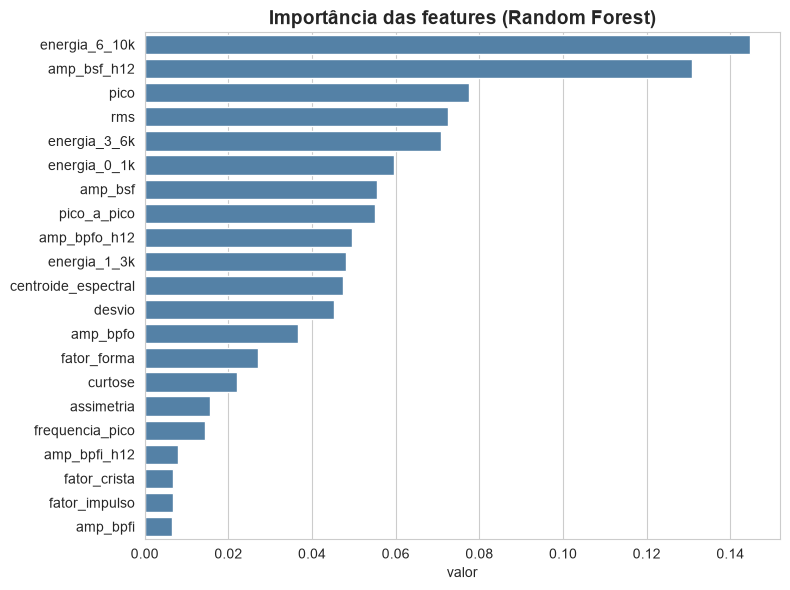

Top 7 por informação mútua: ['energia_3_6k', 'rms', 'desvio', 'energia_1_3k', 'energia_6_10k', 'pico_a_pico', 'amp_bpfo_h12']
RandomForest:


  k=5     F1 CV=0.799  F1 teste=0.726


  k=10    F1 CV=0.862  F1 teste=0.760


  k=15    F1 CV=0.893  F1 teste=0.736


  k=todas F1 CV=0.894  F1 teste=0.721
SVC:


  k=5     F1 CV=0.821  F1 teste=0.630


  k=10    F1 CV=0.853  F1 teste=0.714


  k=15    F1 CV=0.892  F1 teste=0.652


  k=todas F1 CV=0.833  F1 teste=0.650
[tempo] seleção de atributos: 45 s


In [25]:
t0 = time.time()
mi, imp = classic.importancias(X_tr, y_tr, grid['RandomForest']['modelo'])
print('Top 7 por informação mútua:', list(mi.index[:7]))
selecao = {}
for nome in ['RandomForest', 'SVC']:
    print(f'{nome}:')
    selecao[nome] = classic.testar_selectkbest_rapido(grid[nome]['modelo'], X_tr, y_tr, X_te, y_te, cv)
tempos_classico['selecao_atributos'] = time.time() - t0
print(f'[tempo] seleção de atributos: {tempos_classico["selecao_atributos"]:.0f} s')

**As features identificam o rolamento?** Um RF tenta adivinhar *qual dos 12 rolamentos* gerou cada snapshot **Normal**.
Se acertar muito, as features carregam a assinatura da montagem — e parte do "diagnóstico" pode ser reconhecer o rolamento.

In [26]:
t0 = time.time()
df_completo = pd.concat([treino, teste])
d_normal = df_completo[df_completo['classe'] == 'normal'].sort_values(['ensaio', 'rolamento', 'idx'])
rolamento_id = d_normal['ensaio'] + '-' + d_normal['rolamento']
rf_id = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
identidade = {}
for nome_cols, cols in [('todas', COLS_FEATURES), ('relativas', COLS_RELATIVAS)]:
    identidade[nome_cols] = float(cross_val_score(rf_id, matriz_X(d_normal, cols), rolamento_id, cv=cv,
                                                  scoring='accuracy').mean())
print(f'acurácia (CV) para identificar o rolamento entre 12: todas as features = {identidade["todas"]:.3f} | '
      f'sem as de nível absoluto = {identidade["relativas"]:.3f}  (acaso = {1 / 12:.3f})')
tempos_classico['identificacao_rolamento'] = time.time() - t0

acurácia (CV) para identificar o rolamento entre 12: todas as features = 0.986 | sem as de nível absoluto = 0.935  (acaso = 0.083)


### 5.2 Técnica 2 — CNN 1D sobre o sinal bruto (Keras)
CNN 1D pequena (Ince et al. 2016; Kiranyaz et al. 2021) no estilo WDCNN (Zhang et al. 2017): a **1ª convolução é larga**
(64 pontos, passo 8) para filtrar ruído, seguida de 2 blocos com kernel 3; GAP + softmax.
- Entrada: janelas de 2048 pontos (0,1 s ≈ 3,3 rotações), 10 por snapshot, **sem sobreposição**.
- Cache: todas as falhas + Normal com passo 14 no tempo (mantém o split temporal 70/30 da Seção 3).
- Validação: últimos 20% (no tempo) do treino de cada (ensaio, rolamento, classe), por snapshot.
- Previsão do snapshot: **voto majoritário** das 10 janelas. 3 seeds (42, 43, 44).

In [27]:
# Entradas e Saídas: cache da CNN (sinais float16 + metadados)
print('sinais:', sinais.shape, sinais.dtype, '| snapshots por classe e conjunto:')
print(meta.groupby(['classe', 'conjunto']).size().unstack())
assert not set(meta.loc[meta['conjunto'] == 'treino', 'snapshot_id']) & set(meta.loc[meta['conjunto'] == 'teste', 'snapshot_id'])
SEEDS = [42, 43, 44]
NOMES = cnn.NOMES
t_cnn = time.time()

sinais: (4180, 20480) float16 | snapshots por classe e conjunto:
conjunto       teste  treino
classe                      
normal           608    1408
pista_externa    382     894
pista_interna    101     236
rolo             165     386


In [28]:
# Definição
def criar_modelo(tam=2048, n_classes=4):
    """CNN 1D pequena: 1ª convolução larga + 2 blocos kernel 3 (Conv1D + BN + ReLU + MaxPool) + GAP + softmax."""
    entrada = keras.Input(shape=(tam, 1))
    x = entrada
    for filtros, kernel, passo in [(16, 64, 8), (32, 3, 1), (64, 3, 1)]:
        x = layers.Conv1D(filtros, kernel, strides=passo, padding='same')(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling1D(2)(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.3)(x)
    saida = layers.Dense(n_classes, activation='softmax')(x)
    modelo = keras.Model(entrada, saida, name='cnn1d_wdcnn')
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])
    return modelo


def treinar_cnn(dados, seed, epocas=30, batch=64, paciencia=5):
    """Treinamento com class_weight balanceado e EarlyStopping na validação temporal."""
    cnn.fixar_seed(seed)                                # seeds + op determinism
    modelo = criar_modelo()
    parada = keras.callbacks.EarlyStopping(monitor='val_loss', patience=paciencia, restore_best_weights=True)
    t0 = time.time()
    hist = modelo.fit(dados['treino']['X'], dados['treino']['y'], epochs=epocas, batch_size=batch,
                      validation_data=(dados['validacao']['X'], dados['validacao']['y']),
                      class_weight=cnn.pesos_classes(dados['treino']['y']), callbacks=[parada],
                      shuffle=True, verbose=0)
    return modelo, hist.history, time.time() - t0


criar_modelo().summary()

Model: "cnn1d_wdcnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 2048, 1)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 256, 16)        │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256, 16)        │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 128, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 128, 32)        │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 64, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 64, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 32, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,524 (37.20 KB)

 Trainable params: 9,300 (36.33 KB)

 Non-trainable params: 224 (896.00 B)

**Normalização** das janelas, escolhida pela validação (seed 42): *global* (μ e σ do treino) × *z-score por janela*.

In [29]:
# Treinamento: 1 seed com cada normalização; escolhe a de maior F1 macro por janela na validação
dados_norm, modelos_norm, comp_norm = {}, {}, {}
for metodo in ['global', 'janela']:
    dados_norm[metodo] = cnn.preparar_dados(sinais, meta, metodo)        # janelas + split + asserts de vazamento
    modelo, hist, seg = treinar_cnn(dados_norm[metodo], SEEDS[0])
    r = cnn.avaliar(modelo, dados_norm[metodo]['validacao'])
    modelos_norm[metodo] = (modelo, hist, seg)
    comp_norm[metodo] = {'val_f1_macro_janela': r['janela']['f1_macro'], 'val_acuracia_janela': r['janela']['acuracia'],
                         'val_f1_macro_snapshot': r['snapshot']['f1_macro'], 'val_loss_min': float(min(hist['val_loss'])),
                         'epocas': len(hist['loss']), 'tempo_s': seg}
    print(metodo, {k: round(v, 4) for k, v in comp_norm[metodo].items()})
METODO = max(comp_norm, key=lambda k: (comp_norm[k]['val_f1_macro_janela'], -comp_norm[k]['val_loss_min']))
OUTRO = 'janela' if METODO == 'global' else 'global'
print('normalização escolhida:', METODO)

global {'val_f1_macro_janela': 0.9238, 'val_acuracia_janela': 0.9169, 'val_f1_macro_snapshot': 0.9287, 'val_loss_min': 0.1997, 'epocas': 6, 'tempo_s': 47.5299}


janela {'val_f1_macro_janela': 0.8829, 'val_acuracia_janela': 0.8704, 'val_f1_macro_snapshot': 0.904, 'val_loss_min': 0.3211, 'epocas': 6, 'tempo_s': 51.2525}
normalização escolhida: global


In [30]:
# Treinamento das 3 seeds com a normalização escolhida (a seed 42 já foi treinada acima)
dados = dados_norm[METODO]
print({p: dados[p]['X'].shape for p in ['treino', 'validacao', 'teste']})
modelos_cnn, historicos, res_seeds, por_seed = [], {}, [], []
for seed in SEEDS:
    if seed == SEEDS[0]:
        modelo, hist, seg = modelos_norm[METODO]
    else:
        modelo, hist, seg = treinar_cnn(dados, seed)
    # Avaliação (por janela e por snapshot, voto majoritário)
    r = cnn.avaliar(modelo, dados['teste'])
    modelos_cnn.append(modelo)
    historicos[seed] = hist
    res_seeds.append(r)
    por_seed.append({'seed': seed, 'tempo_treino_s': seg, 'epocas': len(hist['loss']),
                     'melhor_epoca': int(np.argmin(hist['val_loss'])) + 1,
                     'janela': r['janela'], 'snapshot': r['snapshot'],
                     'erros_por_grupo_snapshot': cnn.erros_por_grupo(dados['teste']['meta'], r['yhat_snapshot'])})
    print(f'seed {seed}: {seg:.0f} s, {len(hist["loss"])} épocas | janela acc={r["janela"]["acuracia"]:.4f} '
          f'| snapshot acc={r["snapshot"]["acuracia"]:.4f} F1={r["snapshot"]["f1_macro"]:.4f}')
resumo_cnn = cnn.resumir_seeds(res_seeds)

{'treino': (23500, 2048, 1), 'validacao': (5740, 2048, 1), 'teste': (12560, 2048, 1)}


seed 42: 48 s, 6 épocas | janela acc=0.8902 | snapshot acc=0.8893 F1=0.8837


seed 43: 57 s, 7 épocas | janela acc=0.8754 | snapshot acc=0.8766 F1=0.8605


seed 44: 67 s, 9 épocas | janela acc=0.8547 | snapshot acc=0.8487 F1=0.8304


              precision    recall  f1-score   support

      Normal      1.000     0.827     0.905       608
  Pista ext.      0.823     0.911     0.865       382
  Pista int.      0.701     1.000     0.824       101
        Rolo      0.887     1.000     0.940       165

    accuracy                          0.889      1256
   macro avg      0.853     0.935     0.884      1256
weighted avg      0.907     0.889     0.891      1256

               acuracia       f1_macro            tpr            fpr
janela    0.873 ± 0.018  0.859 ± 0.025  0.998 ± 0.002  0.165 ± 0.004
snapshot  0.872 ± 0.021  0.858 ± 0.027  1.000 ± 0.000  0.170 ± 0.009
acurácia por classe (snapshot): {'normal': '0.830 ± 0.009', 'pista_externa': '0.848 ± 0.063', 'pista_interna': '1.000 ± 0.000', 'rolo': '1.000 ± 0.000'}


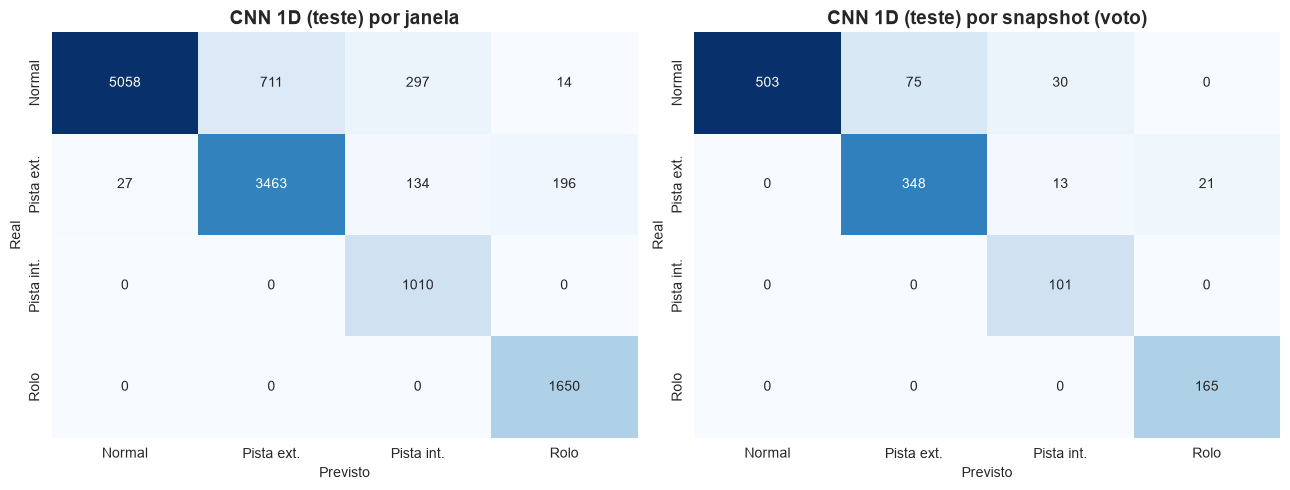

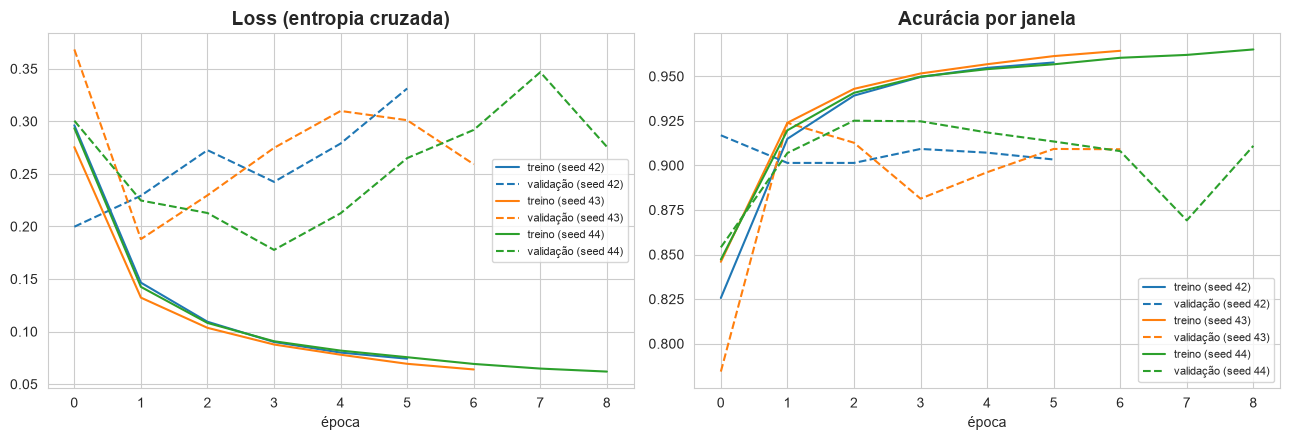

In [31]:
# Avaliação: classification_report por snapshot (seed 42) e média ± desvio das 3 seeds
y_snap = dados['teste']['meta']['classe'].map(cnn.CLASSE_ID).values
print(classification_report(y_snap, res_seeds[0]['yhat_snapshot'], target_names=NOMES, digits=3))
tab_cnn = pd.DataFrame({nivel: {k: f"{v['media']:.3f} ± {v['desvio']:.3f}" for k, v in resumo_cnn[nivel].items()
                                if k != 'acuracia_por_classe'} for nivel in ['janela', 'snapshot']}).T
print(tab_cnn)
print('acurácia por classe (snapshot):',
      {c: f"{v['media']:.3f} ± {v['desvio']:.3f}" for c, v in resumo_cnn['snapshot']['acuracia_por_classe'].items()})
cnn.fig_matrizes(res_seeds[0]['janela']['matriz_confusao'], res_seeds[0]['snapshot']['matriz_confusao'],
                 'CNN 1D (teste)', FIGURAS / 'cnn_matriz_confusao.png')
cnn.fig_curvas(historicos, FIGURAS / 'cnn_curvas_treino.png')

**FPR no Normal de teste completo.** O teste da CNN usa o Normal subamostrado (1 a cada 14). Se o bruto estiver disponível
(rota 3 ou execução local), aplicamos os modelos aos 7.796 snapshots Normais de teste que ficaram fora do cache.
Com só o cache (rota 1/2 no Colab) esta célula é pulada.

In [32]:
modelo_janela = modelos_norm[OUTRO][0]
fpr_completo = None
if RAIZ_BRUTO is not None:
    t0 = time.time()
    configs = {f'{METODO}_s{s}': (m, METODO, dados['stats']) for s, m in zip(SEEDS, modelos_cnn)}
    configs[f'{OUTRO}_s{SEEDS[0]}'] = (modelo_janela, OUTRO, dados_norm[OUTRO]['stats'])
    fpr_completo = cnn.fpr_normal_completo_multi(configs, set(meta['snapshot_id']), RAIZ_BRUTO)
    print(f'{fpr_completo[f"{METODO}_s42"]["n_snapshots"]} snapshots lidos e avaliados em {time.time() - t0:.0f} s')
    print(pd.DataFrame({k: v['fpr_por_rolamento'] for k, v in fpr_completo.items()}).round(3))
    print('FPR:', {k: round(v['fpr'], 4) for k, v in fpr_completo.items()})
else:
    print('dataset bruto ausente: FPR no Normal completo não calculado (ver results/cnn.json)')

dataset bruto ausente: FPR no Normal completo não calculado (ver results/cnn.json)


#### Ablação: a CNN usa o nível absoluto como atalho?
O FPR da CNN (~17%) se concentra no **T1-B3**: depois do intervalo de 148 h sem gravação no T1 (idx 155 → 156) o RMS desse
canal sobe ~22% (provável remontagem/religamento) e, com a normalização *global*, a rede passa a "ouvir" pista interna em todo o
Normal posterior. Hipótese: a rede usa o **nível absoluto** como atalho. Teste: a **mesma CNN com z-score por janela**
(seed 42), que remove média e desvio de cada janela; se a hipótese valer, o FPR do T1-B3 deve cair.

In [33]:
# Degrau de RMS do T1-B3 no buraco do idx 155 -> 156
t1b3 = df[(df['ensaio'] == 'T1') & (df['rolamento'] == 'B3')].set_index('idx')
degrau = {'rms_idx155': float(t1b3.loc[155, 'rms']), 'rms_idx156': float(t1b3.loc[156, 'rms']),
          'gap_h': float(t1b3.loc[156, 'horas_desde_inicio'] - t1b3.loc[155, 'horas_desde_inicio']),
          'rms_mediana_10_155': float(t1b3.loc[10:155, 'rms'].median()),
          'rms_mediana_156_1374': float(t1b3.loc[156:1374, 'rms'].median())}
print({k: round(v, 3) for k, v in degrau.items()},
      f"| salto do RMS: {100 * (degrau['rms_idx156'] / degrau['rms_idx155'] - 1):+.0f}%")

# Avaliação das duas normalizações (seed 42) no teste do cache
res_abl = {METODO: res_seeds[0], OUTRO: cnn.avaliar(modelo_janela, dados_norm[OUTRO]['teste'])}
fpr_rol = {}
for metodo, r in res_abl.items():
    mt = dados_norm[metodo]['teste']['meta']
    normal = (mt['classe'] == 'normal').values
    grupo = (mt['ensaio'] + '_' + mt['rolamento']).values
    alarme = r['yhat_snapshot'] != 0
    fpr_rol[metodo] = {g: float(alarme[normal & (grupo == g)].mean()) for g in sorted(set(grupo[normal]))}
tab_abl = pd.DataFrame(fpr_rol)
tab_abl.columns = [f'FPR {c}' for c in tab_abl.columns]
print(tab_abl.round(3))
print(pd.DataFrame({m: {'acurácia': r['snapshot']['acuracia'], 'F1 macro': r['snapshot']['f1_macro'],
                        'TPR': r['snapshot']['tpr'], 'FPR': r['snapshot']['fpr'],
                        **r['snapshot']['acuracia_por_classe']} for m, r in res_abl.items()}).round(3))

{'rms_idx155': 0.131, 'rms_idx156': 0.16, 'gap_h': 148.426, 'rms_mediana_10_155': 0.131, 'rms_mediana_156_1374': 0.16} | salto do RMS: +22%


       FPR global  FPR janela
T1_B1       0.000       0.000
T1_B2       0.000       0.000
T1_B3       1.000       1.000
T1_B4       0.000       0.367
T2_B1       0.000       0.000
T2_B2       0.000       0.000
T2_B3       0.273       1.000
T2_B4       0.000       0.000
T3_B1       0.000       0.000
T3_B2       0.000       0.000
T3_B3       0.649       0.955
T3_B4       0.000       0.000
               global  janela
acurácia        0.889   0.863
F1 macro        0.884   0.871
TPR             1.000   0.988
FPR             0.173   0.260
normal          0.827   0.740
pista_externa   0.911   0.963
pista_interna   1.000   1.000
rolo            1.000   1.000


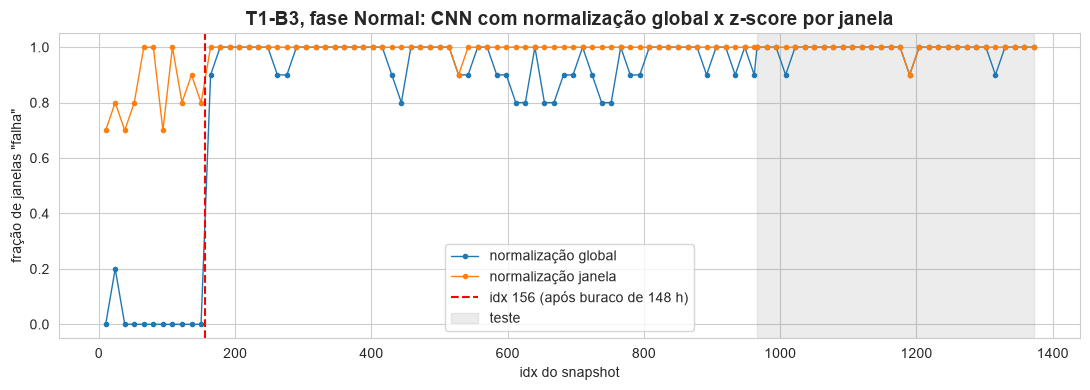

               global  janela
antes_idx156    0.018   0.836
depois_idx156   0.962   0.998


In [34]:
# Fração de janelas previstas como falha ao longo da fase Normal do T1-B3 (snapshots do cache: treino, validação e teste)
m_t1b3 = meta[(meta['ensaio'] == 'T1') & (meta['rolamento'] == 'B3') & (meta['classe'] == 'normal')].sort_values('idx')
curvas_t1b3 = {}
plt.figure(figsize=(11, 4))
for metodo, modelo in [(METODO, modelos_cnn[0]), (OUTRO, modelo_janela)]:
    Xn = cnn.normalizar(cnn.janelas(sinais[m_t1b3.index.values]), metodo, dados_norm[metodo]['stats'])[..., None]
    frac = (modelo.predict(Xn, batch_size=1024, verbose=0).argmax(1).reshape(-1, cnn.N_JANELAS) != 0).mean(1)
    curvas_t1b3[metodo] = frac
    plt.plot(m_t1b3['idx'], frac, 'o-', ms=3, lw=1, label=f'normalização {metodo}')
plt.axvline(156, color='r', ls='--', label='idx 156 (após buraco de 148 h)')
plt.axvspan(m_t1b3.loc[m_t1b3['conjunto'] == 'teste', 'idx'].min(), m_t1b3['idx'].max(), color='gray', alpha=0.15, label='teste')
plt.xlabel('idx do snapshot')
plt.ylabel('fração de janelas "falha"')
plt.title('T1-B3, fase Normal: CNN com normalização global x z-score por janela', fontsize=14, weight='bold')
plt.legend()
plt.tight_layout()
graficos.finalizar(FIGURAS / 'cnn_ablacao_T1B3.png', dpi=100)
antes_depois = {m: {'antes_idx156': float(c[(m_t1b3['idx'] < 156).values].mean()),
                    'depois_idx156': float(c[(m_t1b3['idx'] >= 156).values].mean())} for m, c in curvas_t1b3.items()}
print(pd.DataFrame(antes_depois).round(3))

**Resultado da ablação: a hipótese do nível absoluto não se confirma.** Com z-score por janela o T1-B3 continua com
FPR = 100%, e nessa configuração o Normal dele já é "falha" **antes** do degrau (≈ 0,84 das janelas antes do idx 156, contra ≈ 0,02 na
global). O FPR total piora (≈ 0,17 → ≈ 0,26), puxado por T2-B3, T3-B3 e T1-B4. Sem o nível, a rede se apoia na **forma de onda**
de cada canal, que também identifica o rolamento. Isso vale para as features (98,6% de identificação) e para o sinal bruto:
o degrau explica *quando* o FPR global aparece no T1-B3, mas não *por que* a rede confunde esse rolamento.

In [35]:
ablacao = {
    'descricao': ('mesma CNN (seed 42) com z-score por janela em vez da normalização global; '
                  'FPR por rolamento no Normal de teste do cache (e no Normal de teste completo, se o bruto estiver disponível)'),
    'seed': SEEDS[0], 'degrau_rms_T1B3': degrau,
    'validacao': {m: comp_norm[m] for m in comp_norm},
    'teste_snapshot': {m: {k: v for k, v in r['snapshot'].items()} for m, r in res_abl.items()},
    'fpr_por_rolamento_teste_cache': fpr_rol,
    'T1B3_frac_janelas_falha_normal_cache': antes_depois,
}
if fpr_completo is not None:
    ablacao['fpr_normal_teste_completo'] = {m: fpr_completo[f'{m}_s{SEEDS[0]}'] for m in [METODO, OUTRO]}

#### Referência: `MLPClassifier` sobre as 21 features
Rede densa sobre as features físicas, como referência para a CNN: mesmos snapshots do cache (mesmo treino/teste da CNN),
`Pipeline(StandardScaler, MLPClassifier)` num `GridSearchCV` pequeno com a mesma CV temporal. A comparação mostra o
ganho (ou não) de aprender direto do sinal bruto em vez de usar atributos físicos (Lei et al. 2020).

MLP melhores parâmetros: {'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (64, 32)} | F1 macro CV = 0.874 (31 s)
              precision    recall  f1-score   support

      Normal      1.000     0.849     0.918       608
  Pista ext.      0.741     0.628     0.680       382
  Pista int.      0.407     1.000     0.579       101
        Rolo      0.982     1.000     0.991       165

    accuracy                          0.814      1256
   macro avg      0.783     0.869     0.792      1256
weighted avg      0.871     0.814     0.828      1256

FPR no Normal de teste completo (8404 snapshots): 0.149


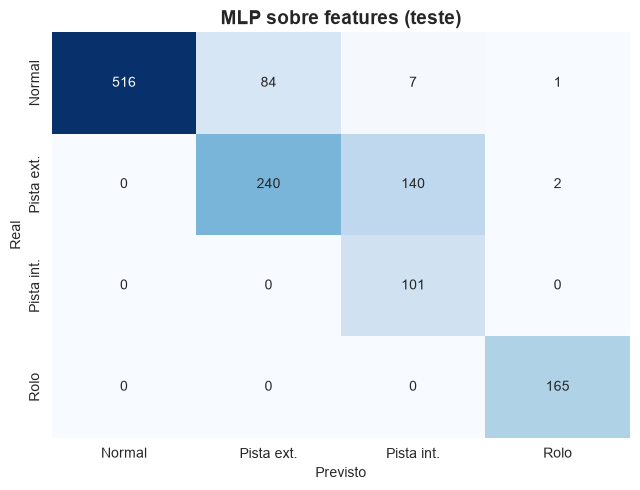

In [36]:
# Entradas e Saídas
rot = pd.read_parquet(dados_cache.ROTULADO)
tr_mlp = rot[rot['snapshot_id'].isin(meta.loc[meta['conjunto'] == 'treino', 'snapshot_id'])].sort_values(['ensaio', 'rolamento', 'idx'])
te_mlp = rot[rot['snapshot_id'].isin(meta.loc[meta['conjunto'] == 'teste', 'snapshot_id'])].sort_values(['ensaio', 'rolamento', 'idx'])
assert not set(tr_mlp['snapshot_id']) & set(te_mlp['snapshot_id']), 'vazamento: snapshot em treino e teste'
Xm_tr, ym_tr = cnn.matriz_features(tr_mlp), tr_mlp['classe'].map(cnn.CLASSE_ID).values
Xm_te, ym_te = cnn.matriz_features(te_mlp), te_mlp['classe'].map(cnn.CLASSE_ID).values

# Definição
pipe_mlp = Pipeline([('scaler', StandardScaler()), ('mlp', MLPClassifier(max_iter=1000, random_state=RANDOM_STATE))])
grade_mlp = {'mlp__hidden_layer_sizes': [(32,), (64,), (64, 32)], 'mlp__alpha': [1e-4, 1e-2, 1.0]}
busca_mlp = GridSearchCV(pipe_mlp, grade_mlp, cv=StratifiedKFold(n_splits=5, shuffle=False), scoring='f1_macro', n_jobs=-1)

# Treinamento
t0 = time.time()
busca_mlp.fit(Xm_tr, ym_tr)
tempo_mlp = time.time() - t0
print('MLP melhores parâmetros:', busca_mlp.best_params_, f'| F1 macro CV = {busca_mlp.best_score_:.3f} ({tempo_mlp:.0f} s)')

# Avaliação
yhat_mlp = busca_mlp.predict(Xm_te)
print(classification_report(ym_te, yhat_mlp, target_names=NOMES, digits=3))
normal_te = rot[(rot['classe'] == 'normal') & (rot['conjunto'] == 'teste')]
res_mlp = {'melhores_parametros': {k: str(v) for k, v in busca_mlp.best_params_.items()},
           'cv_f1_macro': float(busca_mlp.best_score_), 'teste': cnn.metricas(ym_te, yhat_mlp),
           'fpr_normal_teste_completo': float((busca_mlp.predict(cnn.matriz_features(normal_te)) != 0).mean()),
           'n_normal_teste_completo': len(normal_te), 'tempo_grid_s': tempo_mlp,
           'erros_por_grupo': cnn.erros_por_grupo(te_mlp, yhat_mlp)}
print(f"FPR no Normal de teste completo ({len(normal_te)} snapshots): {res_mlp['fpr_normal_teste_completo']:.3f}")
cnn.fig_matriz_unica(res_mlp['teste']['matriz_confusao'], 'MLP sobre features (teste)', FIGURAS / 'cnn_mlp_matriz_confusao.png')

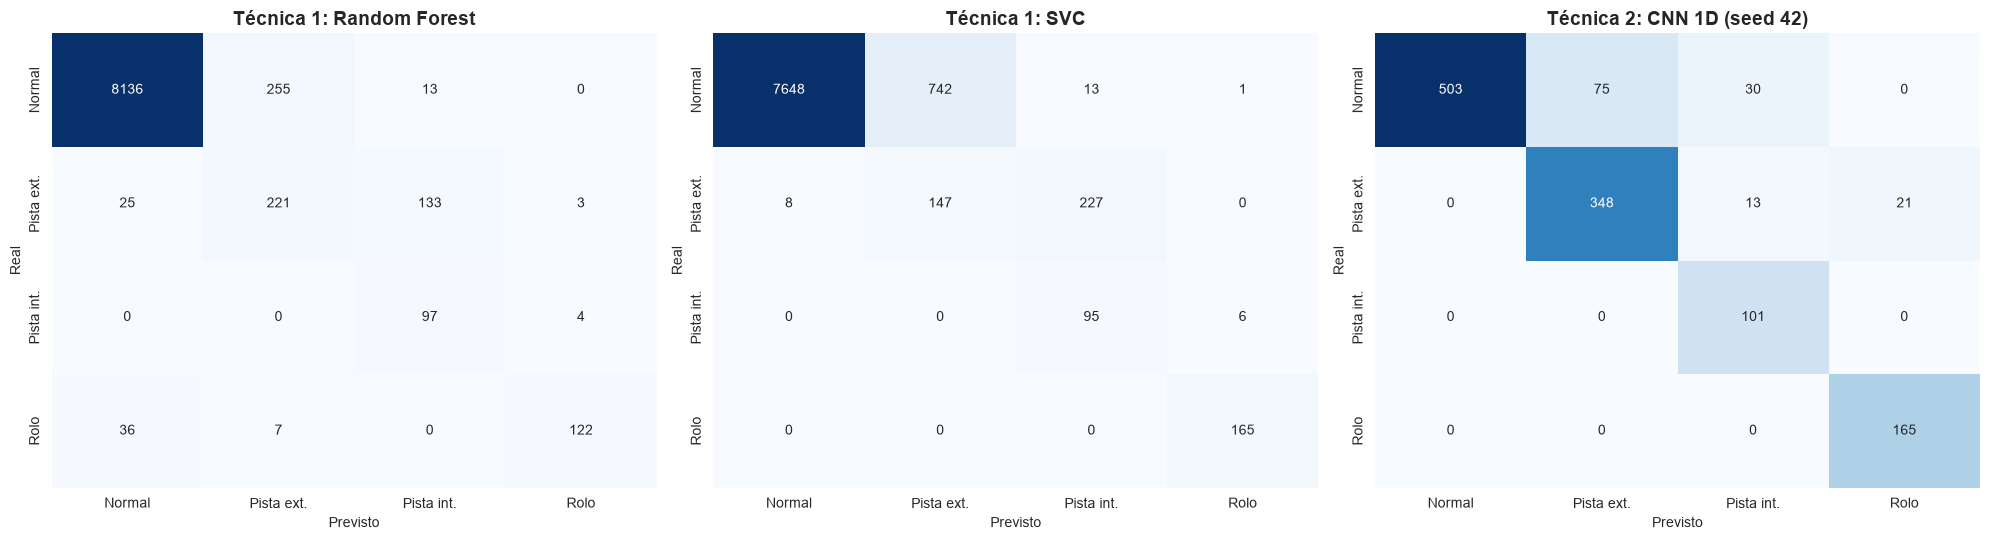

In [37]:
# Matrizes de confusão 4x4 por snapshot: RF e SVC (Técnica 1, teste completo) e CNN (Técnica 2, seed 42, teste do cache)
fig, axs = plt.subplots(1, 3, figsize=(20, 5.5))
graficos.matriz_confusao(avaliacao['RandomForest']['matriz_confusao'], NOMES, 'Técnica 1: Random Forest', ax=axs[0])
graficos.matriz_confusao(avaliacao['SVC']['matriz_confusao'], NOMES, 'Técnica 1: SVC', ax=axs[1])
graficos.matriz_confusao(res_seeds[0]['snapshot']['matriz_confusao'], NOMES, 'Técnica 2: CNN 1D (seed 42)', ax=axs[2])
plt.tight_layout()
graficos.finalizar(FIGURAS / 'matrizes_rf_svc_cnn.png', dpi=100)

## 6. Generalização para um ensaio novo (T3)
Treina com T1 + T2 (a pista externa vem **só** do T2-B1) e testa no T3 inteiro (Normal + pista externa do T3-B3).
Mede se o modelo aprendeu "pista externa" ou só a assinatura do T2-B1.

In [38]:
# Técnica 1: RF e SVC com os hiperparâmetros da CV
t0 = time.time()
modelos_destaque = {n: grid[n]['modelo'] for n in ['RandomForest', 'SVC']}
print('--- todas as features ---')
gen_t1 = classic.generalizacao_t3(df_completo, modelos_destaque)
print('--- só features relativas (sem nível absoluto) ---')
gen_t1_rel = classic.generalizacao_t3(df_completo, modelos_destaque, COLS_RELATIVAS)
ref_t3 = {}
m_t3 = (teste['ensaio'] == 'T3').values
for nome, modelo in modelos_destaque.items():
    rec = recall_score(y_te[m_t3], pred_te[nome][m_t3], labels=['normal', 'pista_externa'], average=None)
    ref_t3[nome] = dict(zip(['normal', 'pista_externa'], rec.round(4).tolist()))
print('referência (split padrão, linhas do T3):', ref_t3)
tempos_classico['generalizacao_T3'] = time.time() - t0

--- todas as features ---


  RandomForest: recall normal=1.000 pista_externa=0.168  TPR=0.174 FPR=0.000


  SVC: recall normal=1.000 pista_externa=0.192  TPR=0.207 FPR=0.000
--- só features relativas (sem nível absoluto) ---


  RandomForest: recall normal=1.000 pista_externa=0.171  TPR=0.174 FPR=0.000


  SVC: recall normal=0.961 pista_externa=0.168  TPR=0.410 FPR=0.039
referência (split padrão, linhas do T3): {'RandomForest': {'normal': 0.9589, 'pista_externa': 0.4372}, 'SVC': {'normal': 0.8806, 'pista_externa': 0.336}}


In [39]:
# Técnica 2: a mesma CNN treinada sem nenhum snapshot do T3
meta_sem_t3 = meta.copy()
eh_t3 = meta_sem_t3['ensaio'] == 'T3'
meta_sem_t3.loc[eh_t3, 'conjunto'] = 'teste'                               # T3 inteiro vira teste
meta_sem_t3 = meta_sem_t3[eh_t3 | (meta_sem_t3['conjunto'] == 'treino')]   # fora do T3, só o treino original
dados_gen = cnn.preparar_dados(sinais, meta_sem_t3, METODO)
assert (dados_gen['teste']['meta']['ensaio'] == 'T3').all()
gen_cnn = []
for seed in SEEDS:
    modelo, _, _ = treinar_cnn(dados_gen, seed)
    r = cnn.avaliar(modelo, dados_gen['teste'])
    gen_cnn.append({'seed': seed, 'snapshot': r['snapshot']})
    print(f'seed {seed}: recall pista externa = {r["snapshot"]["acuracia_por_classe"]["pista_externa"]:.3f} | '
          f'TPR = {r["snapshot"]["tpr"]:.3f} | FPR = {r["snapshot"]["fpr"]:.3f}')
res_gen_cnn = {
    'descricao': 'treino sem T3; teste = todos os snapshots T3 do cache (normal + pista externa)',
    'n_teste_snapshots': int(len(dados_gen['teste']['meta'])), 'por_seed': gen_cnn,
    'resumo_snapshot': {
        'recall_pista_externa': cnn.media_desvio([s['snapshot']['acuracia_por_classe']['pista_externa'] for s in gen_cnn]),
        'fpr': cnn.media_desvio([s['snapshot']['fpr'] for s in gen_cnn]),
        'tpr': cnn.media_desvio([s['snapshot']['tpr'] for s in gen_cnn])}}
del dados_gen

tab_gen = pd.DataFrame({
    'RF': {'recall pista ext. (T3)': gen_t1['RandomForest']['acuracia_por_classe']['pista_externa'],
           'FPR (T3)': gen_t1['RandomForest']['FPR_falha'], 'referência split padrão': ref_t3['RandomForest']['pista_externa']},
    'SVC': {'recall pista ext. (T3)': gen_t1['SVC']['acuracia_por_classe']['pista_externa'],
            'FPR (T3)': gen_t1['SVC']['FPR_falha'], 'referência split padrão': ref_t3['SVC']['pista_externa']},
    'CNN (3 seeds)': {'recall pista ext. (T3)': res_gen_cnn['resumo_snapshot']['recall_pista_externa']['media'],
                      'FPR (T3)': res_gen_cnn['resumo_snapshot']['fpr']['media'],
                      'referência split padrão': resumo_cnn['snapshot']['acuracia_por_classe']['pista_externa']['media']},
}).T
print(tab_gen.round(3))

seed 42: recall pista externa = 0.052 | TPR = 0.196 | FPR = 0.000


seed 43: recall pista externa = 0.140 | TPR = 0.196 | FPR = 0.000


seed 44: recall pista externa = 0.087 | TPR = 0.196 | FPR = 0.000
               recall pista ext. (T3)  FPR (T3)  referência split padrão
RF                              0.168       0.0                    0.437
SVC                             0.192       0.0                    0.336
CNN (3 seeds)                   0.093       0.0                    0.848


In [40]:
# Grava os resultados da Técnica 1 e da Técnica 2 (em cnn.json, preserva as chaves geradas por src/cnn.py que não são recalculadas aqui)
res_classico = {
    'features': COLS_FEATURES, 'features_log10': classic.COLS_LOG,
    'gridsearch': {n: {'f1_macro_cv': r['f1_cv'], 'melhores_params': r['params'], 'tempo_s': r['tempo_s']}
                   for n, r in grid.items()},
    'teste': avaliacao, 'melhor_modelo_cv': melhor_cv, 'normal_previsto_falha_por_rolamento': erros_normal,
    'mutual_info': mi.round(4).to_dict(), 'importancia_rf': imp.round(4).to_dict(),
    'selectkbest_mutual_info': selecao,
    'generalizacao_T3': {'todas_features': gen_t1, 'features_relativas': gen_t1_rel,
                         'referencia_split_padrao_linhas_T3': ref_t3},
    'identificacao_rolamento_acuracia_cv': identidade,
    'tempos_s': tempos_classico, 'tempo_total_s': float(sum(tempos_classico.values())),
}
classic.salvar_json(res_classico, RESULTADOS / 'classico.json')

caminho_cnn = RESULTADOS / 'cnn.json'
res_cnn = json.loads(caminho_cnn.read_text(encoding='utf-8')) if caminho_cnn.exists() else {}
res_cnn.update({
    'cache_mb': dados_cache.CNN_CACHE.stat().st_size / 2**20,
    'cache_contagens': meta.groupby(['classe', 'conjunto']).size().unstack().to_dict(),
    'normalizacao': {'escolhida': METODO, 'comparacao_validacao_seed42': comp_norm},
    'n_janelas': {p: int(len(dados[p]['y'])) for p in ['treino', 'validacao', 'teste']},
    'n_parametros': int(modelos_cnn[0].count_params()),
    'por_seed': por_seed, 'resumo': resumo_cnn,
    'tempo_medio_por_seed_s': float(np.mean([p['tempo_treino_s'] for p in por_seed])),
    'mlp': res_mlp, 'generalizacao_sem_T3': res_gen_cnn, 'ablacao_zscore_janela': ablacao,
})
if fpr_completo is not None:
    chaves = [f'{METODO}_s{s}' for s in SEEDS]
    fprs = [fpr_completo[c]['fpr'] for c in chaves]
    res_cnn['fpr_normal_teste_ampliado'] = {
        'n_snapshots': fpr_completo[chaves[0]]['n_snapshots'], 'fpr_por_seed': fprs, 'fpr_media': cnn.media_desvio(fprs),
        'fpr_por_rolamento': {g: [fpr_completo[c]['fpr_por_rolamento'][g] for c in chaves]
                              for g in fpr_completo[chaves[0]]['fpr_por_rolamento']}}
TEMPOS['5.2 + 6. CNN, MLP e generalização'] = time.time() - t_cnn
res_cnn['tempo_total_s'] = TEMPOS['5.2 + 6. CNN, MLP e generalização']
with open(caminho_cnn, 'w', encoding='utf-8') as f:
    json.dump(cnn._sem_numpy(res_cnn), f, indent=2, ensure_ascii=False)
TEMPOS['5.1 + 6. Técnica 1'] = res_classico['tempo_total_s']
print({k: f'{v:.0f} s' for k, v in TEMPOS.items()})

{'0. obter dados': '27 s', '4. detecção': '26 s', '5.2 + 6. CNN, MLP e generalização': '453 s', '5.1 + 6. Técnica 1': '130 s'}


## 7. Checagem física: espectro de envelope de um acerto e de um erro
Se o classificador acerta pelos motivos certos, um snapshot de pista externa deve mostrar pico em BPFO (236 Hz) e no
2×BPFO no espectro do envelope (Randall & Antoni 2011). Pegamos, no teste, um snapshot de **pista externa** que o RF
**acertou** e um que ele **confundiu com pista interna** (a confusão mais comum), do mesmo rolamento.

T3-B3: 108 acertos e 113 erros PE -> PI no teste


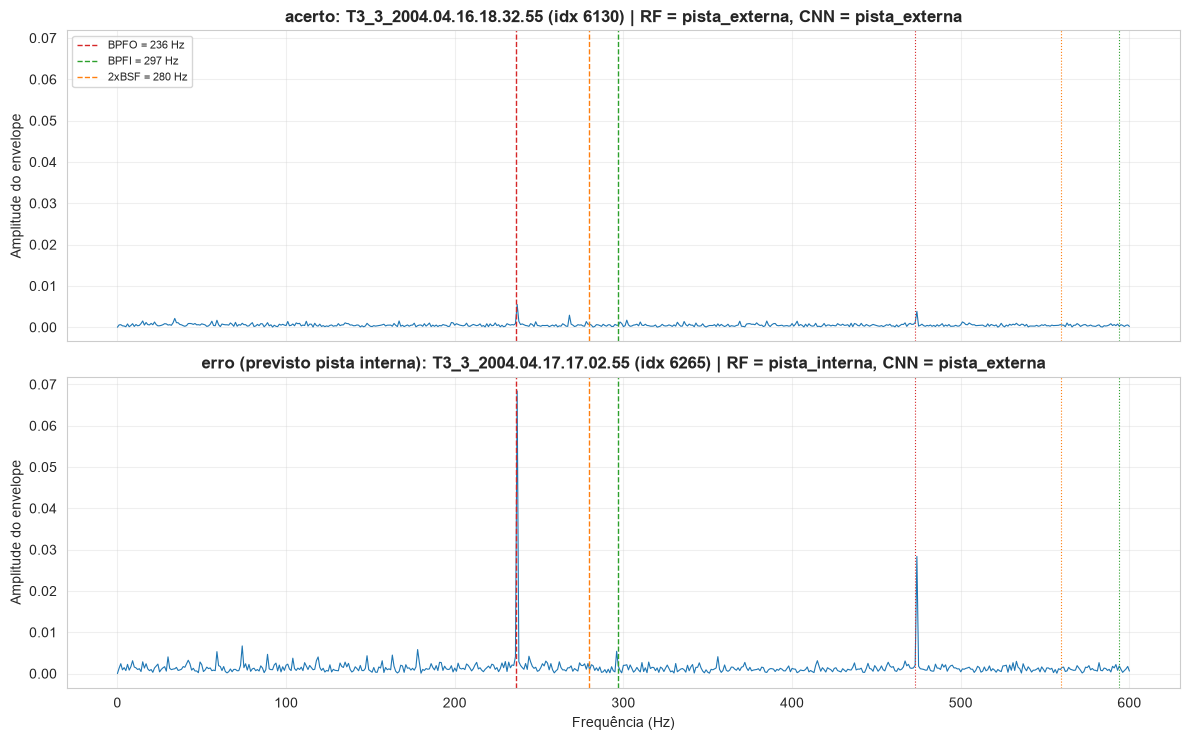

                acerto  erro (previsto pista interna)  \
rms             0.0856                         0.2474   
curtose         3.2053                         3.1951   
energia_3_6k    0.0015                         0.0209   
energia_6_10k   0.0008                         0.0032   
amp_bpfo       30.9737                       224.6725   
amp_bpfi        9.6011                        17.6947   
amp_bsf         7.7221                         8.5467   

               mediana treino pista_externa  mediana treino pista_interna  
rms                                  0.0732                        0.1687  
curtose                              3.1916                        9.3672  
energia_3_6k                         0.0008                        0.0034  
energia_6_10k                        0.0005                        0.0018  
amp_bpfo                             8.2202                       10.2319  
amp_bpfi                             6.9042                       12.8204  
amp_bsf    

In [41]:
pe = teste[(teste['classe'] == 'pista_externa')].copy()
pe['pred_rf'] = pred_te['RandomForest'][(teste['classe'] == 'pista_externa').values]
pe['rol'] = pe['ensaio'] + '-' + pe['rolamento']
erros_pe = pe[pe['pred_rf'] == 'pista_interna']
rol_alvo = erros_pe['rol'].value_counts().index[0]                      # rolamento com mais erros PE -> PI
erros_rol = erros_pe[erros_pe['rol'] == rol_alvo].sort_values('idx')
acertos_rol = pe[(pe['rol'] == rol_alvo) & (pe['pred_rf'] == 'pista_externa')].sort_values('idx')
print(f'{rol_alvo}: {len(acertos_rol)} acertos e {len(erros_rol)} erros PE -> PI no teste')
exemplos = {'acerto': acertos_rol.iloc[len(acertos_rol) // 2], 'erro (previsto pista interna)': erros_rol.iloc[len(erros_rol) // 2]}

# previsão da CNN (seed 42) nos mesmos snapshots
pred_cnn = pd.Series([CLASSES[i] for i in res_seeds[0]['yhat_snapshot']], index=dados['teste']['meta']['snapshot_id'].values)

fig, axs = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, sharey=True)
for ax, (rotulo, linha) in zip(axs, exemplos.items()):
    f, esp = features.espectro_envelope(sinal_de(linha['snapshot_id']), FS)
    graficos.espectro_envelope_painel(ax, f, esp, FREQS, f'{rotulo}: {linha["snapshot_id"]} (idx {linha["idx"]}) | '
                                      f'RF = {linha["pred_rf"]}, CNN = {pred_cnn.get(linha["snapshot_id"], "-")}')
axs[0].legend(fontsize=8)
axs[1].set_xlabel('Frequência (Hz)')
plt.tight_layout()
graficos.finalizar(FIGURAS / 'checagem_fisica_envelope.png', dpi=100)

# Features dos dois exemplos x mediana das classes no treino (nível absoluto x envelope)
cols_ver = ['rms', 'curtose', 'energia_3_6k', 'energia_6_10k', 'amp_bpfo', 'amp_bpfi', 'amp_bsf']
tab_fis = pd.DataFrame({r: l[cols_ver].astype(float) for r, l in exemplos.items()})
for c in ['pista_externa', 'pista_interna']:
    tab_fis[f'mediana treino {c}'] = treino.loc[treino['classe'] == c, cols_ver].median()
print(tab_fis.round(4))

## 8. Tabela-resumo
Colunas: Dataset | Técnica | Tipo de falha identificada | TPR | FPR | Acurácia por classe. Para os detectores (binários), a "acurácia por classe" é a fração de cada tipo de falha detectada
(e 1 − FPR para o Normal). Para a CNN, média ± desvio de 3 seeds, por snapshot (voto das 10 janelas).

In [42]:
def fmt(v, casas=3):
    """Número com vírgula decimal."""
    return f'{v:.{casas}f}'.replace('.', ',')


def fmt_md(d):
    """média ± desvio com vírgula."""
    return f"{fmt(d['media'])} ± {fmt(d['desvio'])}"


NOME_CLASSE = {'normal': 'Normal', 'pista_externa': 'Pista ext.', 'pista_interna': 'Pista int.', 'rolo': 'Rolo'}
n_n, n_f = int((yb_te == 0).sum()), int((yb_te == 1).sum())
ds_completo = f'IMS T1+T2+T3, teste temporal ({n_n} N / {n_f} F)'
cm_cnn = meta[meta['conjunto'] == 'teste']['classe'].value_counts()
ds_cache = f"IMS, cache da CNN, teste ({cm_cnn['normal']} N / {cm_cnn.drop('normal').sum()} F)"

linhas = []
for chave, tecnica in [('D1', 'Detecção D1: limiar μ+3σ (log RMS, curtose)'),
                       ('D2', 'Detecção D2: PCA + KMeans (distância ao centróide)'),
                       ('D3_RF', 'Detecção D3: Random Forest binário (limiar de Youden)')]:
    m, t = met_det[chave], tpr_tipo[chave]
    acc = '; '.join([f'Normal {fmt(1 - m["FPR"])}'] + [f'{NOME_CLASSE[c]} {fmt(v)}' for c, v in t.items()])
    linhas.append({'Dataset': ds_completo, 'Técnica': tecnica, 'Tipo de falha identificada': 'Normal × Falha (qualquer tipo)',
                   'TPR': m['TPR'], 'FPR': m['FPR'], 'Acurácia por classe': acc, 'TPR_txt': fmt(m['TPR']), 'FPR_txt': fmt(m['FPR'])})
for chave, tecnica in [('RandomForest', 'Técnica 1: Random Forest (features)'), ('SVC', 'Técnica 1: SVC (features)')]:
    a = avaliacao[chave]
    acc = '; '.join(f'{NOME_CLASSE[c]} {fmt(v)}' for c, v in a['acuracia_por_classe'].items())
    linhas.append({'Dataset': ds_completo, 'Técnica': tecnica, 'Tipo de falha identificada': 'Pista ext. / Pista int. / Rolo',
                   'TPR': a['TPR_falha'], 'FPR': a['FPR_falha'], 'Acurácia por classe': acc,
                   'TPR_txt': fmt(a['TPR_falha']), 'FPR_txt': fmt(a['FPR_falha'])})
rs = resumo_cnn['snapshot']
linhas.append({'Dataset': ds_cache, 'Técnica': 'Técnica 2: CNN 1D (sinal bruto, 3 seeds)',
               'Tipo de falha identificada': 'Pista ext. / Pista int. / Rolo', 'TPR': rs['tpr']['media'], 'FPR': rs['fpr']['media'],
               'Acurácia por classe': '; '.join(f'{NOME_CLASSE[c]} {fmt_md(v)}' for c, v in rs['acuracia_por_classe'].items()),
               'TPR_txt': fmt_md(rs['tpr']), 'FPR_txt': fmt_md(rs['fpr'])})
tm = res_mlp['teste']
linhas.append({'Dataset': ds_cache, 'Técnica': 'Comparação: MLPClassifier (features)',
               'Tipo de falha identificada': 'Pista ext. / Pista int. / Rolo', 'TPR': tm['tpr'], 'FPR': tm['fpr'],
               'Acurácia por classe': '; '.join(f'{NOME_CLASSE[c]} {fmt(v)}' for c, v in tm['acuracia_por_classe'].items()),
               'TPR_txt': fmt(tm['tpr']), 'FPR_txt': fmt(tm['fpr'])})
tabela = pd.DataFrame(linhas)

# CSV (números com ponto) e Markdown (vírgula decimal)
colunas = ['Dataset', 'Técnica', 'Tipo de falha identificada', 'Taxa de detecção (TPR)', 'Falso positivo (FPR)', 'Acurácia por classe']
tabela_csv = tabela.rename(columns={'TPR': 'Taxa de detecção (TPR)', 'FPR': 'Falso positivo (FPR)'})[colunas]
tabela_csv.round(4).to_csv(RESULTADOS / 'tabela_resumo.csv', index=False, encoding='utf-8')
md = ['| ' + ' | '.join(colunas) + ' |', '|' + '---|' * len(colunas)]
for _, l in tabela.iterrows():
    md.append(f"| {l['Dataset']} | {l['Técnica']} | {l['Tipo de falha identificada']} | {l['TPR_txt']} | {l['FPR_txt']} | {l['Acurácia por classe']} |")
(RESULTADOS / 'tabela_resumo.md').write_text('\n'.join(md) + '\n', encoding='utf-8')

from IPython.display import Markdown, display
display(Markdown('\n'.join(md)))

| Dataset | Técnica | Tipo de falha identificada | Taxa de detecção (TPR) | Falso positivo (FPR) | Acurácia por classe |
|---|---|---|---|---|---|
| IMS T1+T2+T3, teste temporal (8404 N / 648 F) | Detecção D1: limiar μ+3σ (log RMS, curtose) | Normal × Falha (qualquer tipo) | 0,461 | 0,016 | Normal 0,984; Pista ext. 0,424; Pista int. 0,812; Rolo 0,333 |
| IMS T1+T2+T3, teste temporal (8404 N / 648 F) | Detecção D2: PCA + KMeans (distância ao centróide) | Normal × Falha (qualquer tipo) | 0,935 | 0,013 | Normal 0,987; Pista ext. 0,945; Pista int. 0,970; Rolo 0,891 |
| IMS T1+T2+T3, teste temporal (8404 N / 648 F) | Detecção D3: Random Forest binário (limiar de Youden) | Normal × Falha (qualquer tipo) | 0,994 | 0,053 | Normal 0,947; Pista ext. 0,990; Pista int. 1,000; Rolo 1,000 |
| IMS T1+T2+T3, teste temporal (8404 N / 648 F) | Técnica 1: Random Forest (features) | Pista ext. / Pista int. / Rolo | 0,906 | 0,032 | Normal 0,968; Pista ext. 0,579; Pista int. 0,960; Rolo 0,739 |
| IMS T1+T2+T3, teste temporal (8404 N / 648 F) | Técnica 1: SVC (features) | Pista ext. / Pista int. / Rolo | 0,988 | 0,090 | Normal 0,910; Pista ext. 0,385; Pista int. 0,941; Rolo 1,000 |
| IMS, cache da CNN, teste (608 N / 648 F) | Técnica 2: CNN 1D (sinal bruto, 3 seeds) | Pista ext. / Pista int. / Rolo | 1,000 ± 0,000 | 0,170 ± 0,009 | Normal 0,830 ± 0,009; Pista ext. 0,848 ± 0,063; Pista int. 1,000 ± 0,000; Rolo 1,000 ± 0,000 |
| IMS, cache da CNN, teste (608 N / 648 F) | Comparação: MLPClassifier (features) | Pista ext. / Pista int. / Rolo | 1,000 | 0,151 | Normal 0,849; Pista ext. 0,628; Pista int. 1,000; Rolo 1,000 |

Matrizes de confusão 4×4 completas: `results/figuras/matrizes_rf_svc_cnn.png` (RF, SVC, CNN), `classico_matriz_*.png`,
`cnn_matriz_confusao.png` e `cnn_mlp_matriz_confusao.png`.

In [43]:
TEMPOS['total'] = time.time() - T_INICIO
print('Tempo de cada etapa:')
for etapa, seg in TEMPOS.items():
    print(f'  {etapa:40s} {seg:7.1f} s')

Tempo de cada etapa:
  0. obter dados                              27.0 s
  4. detecção                                 25.8 s
  5.2 + 6. CNN, MLP e generalização          452.8 s
  5.1 + 6. Técnica 1                         129.8 s
  total                                      665.9 s


## 9. Discussão crítica e conclusões

**Detecção.** O D2 (PCA + KMeans ajustados só no Normal do treino) teve o melhor compromisso entre sensibilidade e alarmes
falsos: TPR ≈ 0,94 com FPR ≈ 1,3% no teste e primeiro alarme persistente antes ou junto do início rotulado em 3 dos 4
rolamentos que falharam. O D1, com limiar μ+3σ global, sofre com níveis basais diferentes entre rolamentos (a curtose
basal do T1-B4 já fica acima do limiar), limitação conhecida de indicadores escalares como RMS e curtose (Randall 2011).
O D3 supervisionado detecta quase todas as falhas (TPR ≈ 0,99), mas tem FPR maior (≈ 5%) e exige exemplos rotulados de
falha, que na prática raramente existem.

**Diagnóstico.** RF, SVC e CNN reconhecem bem pista interna e rolo; a pista externa é a classe mais difícil. Cada classe de
falha vem de apenas 1 ou 2 rolamentos, e as features identificam o rolamento de origem com ~99% de acerto (~94% sem as de
nível absoluto). Parte do "diagnóstico", portanto, é reconhecer a montagem, e não só o tipo de defeito: é o mesmo cuidado
que Smith & Randall (2015) recomendam ao interpretar resultados em bancadas de referência.

**CNN 1D.** O FPR ≈ 17% da CNN vem quase todo do T1-B3 (100%) e do T3-B3 (~65%). No T1-B3 ele começa num degrau de RMS
de ~+22% após 148 h sem gravação. A ablação com z-score por janela **não** resolve: o FPR sobe para ≈ 0,26 e o T1-B3
continua em 100%, ou seja, a rede reconhece o rolamento pela forma do sinal, e não só pelo nível. Frente ao `MLPClassifier`
sobre as features, a CNN tem recall maior na pista externa (≈ 0,85 × 0,63) e FPR semelhante (≈ 0,17 × 0,15): aprender
direto do sinal ajuda a separar os tipos de falha, mas não elimina os alarmes falsos.

**Generalização para outro ensaio.** Treinando sem o T3, o recall da pista externa do T3-B3 cai para ≈ 0,1–0,2 em RF, SVC
e CNN. Com um único rolamento de pista externa no treino (T2-B1), os modelos aprendem a assinatura desse rolamento, e não um
conceito geral de defeito na pista externa; o sinal fraco do T3 (Gousseau et al. 2016) agrava o problema.

**Checagem física.** O snapshot de pista externa confundido com pista interna ainda mostra o pico em BPFO no espectro do
envelope: o erro vem das features de nível (energia/RMS), não da ausência da assinatura física (Randall & Antoni 2011).

**Limitações.** (i) Os rótulos são derivados: o início da falha é estimado, não observado. (ii) Há poucos rolamentos por
classe. (iii) O teste temporal contém o estágio mais severo da degradação, então a AUC alta não mede detecção precoce;
quem mede é a antecedência. (iv) A CNN usa o Normal subamostrado, de modo que acurácia e F1 da CNN e da Técnica 1 não são
diretamente comparáveis; o FPR é.

**Conclusão.** Para a detecção, um modelo não supervisionado simples, ajustado só na fase saudável (D2), atinge FPR baixo
e dá antecedência útil. Para o diagnóstico, os bons resultados no split temporal não se mantêm num ensaio novo: um
classificador confiável de tipo de falha no IMS exigiria mais rolamentos por classe ou uma validação que separe rolamentos
inteiros entre treino e teste.

## Referências

BREIMAN, L. Random forests. **Machine Learning**, v. 45, n. 1, p. 5–32, 2001. DOI: 10.1023/A:1010933404324.

CORTES, C.; VAPNIK, V. Support-vector networks. **Machine Learning**, v. 20, n. 3, p. 273–297, 1995. DOI: 10.1007/BF00994018.

GOUSSEAU, W.; ANTONI, J.; GIRARDIN, F.; GRIFFATON, J. Analysis of the Rolling Element Bearing data set of the Center for
Intelligent Maintenance Systems of the University of Cincinnati. In: CM2016 – INTERNATIONAL CONFERENCE ON CONDITION
MONITORING, 2016, Charenton, França. HAL: hal-01715193. Disponível em: https://hal.science/hal-01715193/document.
Acesso em: 4 nov. 2026.

HASANI, R. M.; WANG, G.; GROSU, R. **An automated auto-encoder correlation-based health-monitoring and prognostic method
for machine bearings**. arXiv:1703.06272, 2017. Disponível em: https://arxiv.org/abs/1703.06272. Acesso em: 4 nov. 2026.

INCE, T.; KIRANYAZ, S.; EREN, L.; ASKAR, M.; GABBOUJ, M. Real-time motor fault detection by 1-D convolutional neural
networks. **IEEE Transactions on Industrial Electronics**, v. 63, n. 11, p. 7067–7075, 2016. DOI: 10.1109/TIE.2016.2582729.

JOLLIFFE, I. T.; CADIMA, J. Principal component analysis: a review and recent developments. **Philosophical Transactions
of the Royal Society A**, v. 374, n. 2065, art. 20150202, 2016. DOI: 10.1098/rsta.2015.0202.

KIRANYAZ, S.; AVCI, O.; ABDELJABER, O.; INCE, T.; GABBOUJ, M.; INMAN, D. J. 1D convolutional neural networks and
applications: a survey. **Mechanical Systems and Signal Processing**, v. 151, art. 107398, 2021.
DOI: 10.1016/j.ymssp.2020.107398.

LEE, J.; QIU, H.; YU, G.; LIN, J.; REXNORD TECHNICAL SERVICES. **Bearing Data Set**. IMS, University of Cincinnati.
NASA Prognostics Data Repository, NASA Ames Research Center, Moffett Field, CA, 2007. Disponível em:
https://www.nasa.gov/intelligent-systems-division/discovery-and-systems-health/pcoe/pcoe-data-set-repository/.
Acesso em: 4 nov. 2026.

LEI, Y.; YANG, B.; JIANG, X.; JIA, F.; LI, N.; NANDI, A. K. Applications of machine learning to machine fault diagnosis:
a review and roadmap. **Mechanical Systems and Signal Processing**, v. 138, art. 106587, 2020.
DOI: 10.1016/j.ymssp.2019.106587.

MACQUEEN, J. Some methods for classification and analysis of multivariate observations. In: BERKELEY SYMPOSIUM ON
MATHEMATICAL STATISTICS AND PROBABILITY, 5., 1965–1966, Berkeley. **Proceedings** [...]. Berkeley: University of
California Press, 1967. v. 1, p. 281–297.

MOUSAEI SHIR-MOHAMMAD, B. et al. **When linear RUL labels disagree with vibration degradation: a stage-aware target and
dual-scale predictor evaluated on XJTU-SY and IMS**. arXiv:2607.28115, 2026. Disponível em:
https://arxiv.org/abs/2607.28115. Acesso em: 4 nov. 2026.

PEDREGOSA, F. et al. Scikit-learn: machine learning in Python. **Journal of Machine Learning Research**, v. 12, n. 85,
p. 2825–2830, 2011. Disponível em: https://jmlr.org/papers/v12/pedregosa11a.html. Acesso em: 4 nov. 2026.

QIN, X.; LI, Q.; DONG, X.; LV, S. The fault diagnosis of rolling bearing based on ensemble empirical mode decomposition
and random forest. **Shock and Vibration**, v. 2017, art. 2623081, p. 1–9, 2017. DOI: 10.1155/2017/2623081.

QIU, H.; LEE, J.; LIN, J.; YU, G. Wavelet filter-based weak signature detection method and its application on rolling
element bearing prognostics. **Journal of Sound and Vibration**, v. 289, n. 4–5, p. 1066–1090, 2006.
DOI: 10.1016/j.jsv.2005.03.007.

RANDALL, R. B. **Vibration-based condition monitoring**: industrial, aerospace and automotive applications. Chichester:
Wiley, 2011. DOI: 10.1002/9780470977668.

RANDALL, R. B.; ANTONI, J. Rolling element bearing diagnostics: a tutorial. **Mechanical Systems and Signal Processing**,
v. 25, n. 2, p. 485–520, 2011. DOI: 10.1016/j.ymssp.2010.07.017.

REHAB, A.; ALI, I.; GOMAA, W.; FORS, M. N. Bearings fault detection using hidden Markov models and principal component
analysis enhanced features. **PHM Society European Conference**, v. 6, n. 1, art. 11, p. 360–368, 2021.
DOI: 10.36001/phme.2021.v6i1.2947.

ROUSSEEUW, P. J. Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. **Journal of
Computational and Applied Mathematics**, v. 20, p. 53–65, 1987. DOI: 10.1016/0377-0427(87)90125-7.

SMITH, W. A.; RANDALL, R. B. Rolling element bearing diagnostics using the Case Western Reserve University data: a
benchmark study. **Mechanical Systems and Signal Processing**, v. 64–65, p. 100–131, 2015.
DOI: 10.1016/j.ymssp.2015.04.021.

WARD, J. H. Hierarchical grouping to optimize an objective function. **Journal of the American Statistical
Association**, v. 58, n. 301, p. 236–244, 1963. DOI: 10.1080/01621459.1963.10500845.

WIDODO, A.; YANG, B.-S. Support vector machine in machine condition monitoring and fault diagnosis. **Mechanical Systems
and Signal Processing**, v. 21, n. 6, p. 2560–2574, 2007. DOI: 10.1016/j.ymssp.2006.12.007.

YOUDEN, W. J. Index for rating diagnostic tests. **Cancer**, v. 3, n. 1, p. 32–35, 1950.

ZHANG, W.; PENG, G.; LI, C.; CHEN, Y.; ZHANG, Z. A new deep learning model for fault diagnosis with good anti-noise and
domain adaptation ability on raw vibration signals. **Sensors**, v. 17, n. 2, art. 425, 2017. DOI: 10.3390/s17020425.